# Conformal Risk Control for Startup Success Prediction

A classifier predicts whether a startup succeeds; Conformal Risk Control (CRC,
Angelopoulos et al., 2024) then picks the decision threshold that bounds the
**False Negative Rate** of the success class at a target level `alpha`. Missing a
successful startup is the costly error, so the FNR is the risk under control.

Three questions:

- **RQ1** — does a single, global CRC threshold keep the test FNR at `alpha`, and
  what does it cost on the other metrics?
- **RQ2** — with that global threshold, how is the FNR distributed across
  subgroups (industry sector, founding-year cohort)?
- **RQ3** — what changes when the threshold is calibrated per subgroup
  (group-level, or Mondrian, CRC)?

## Weights & Biases is optional

With `USE_WANDB = False` every model of the sweep grid in `config.yaml` is trained
locally and nothing is logged remotely; the results are kept in memory, which is
all the cells below need. With it on, a sweep agent drives the same runs and logs
them to the entity and project read from `.env`. It is the same `train` function
either way.

In [1]:
%load_ext autoreload
%autoreload 2

import os
from itertools import product
from types import SimpleNamespace
from dotenv import load_dotenv 
import yaml

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.impute import KNNImputer

from src.encoding import apply_frequency_encoding, fit_frequency_encoding
from src.models import build
from src.utils import (set_seed,
                       run_conformal_fnr_experiment,
                       run_conformal_fnr_group_calibrated, plot_conformal_fnr,
                       assign_model_colors, fnr_by_group_table,
                       crc_summary_tables, plot_crc_metric_boxplots,
                       plot_fnr_by_group_boxplots, plot_fnr_by_group_lines)


from sklearn.metrics import accuracy_score, roc_auc_score
import wandb
import matplotlib.pyplot as plt 


import scipy.integrate
if not hasattr(np, 'trapz'):
    np.trapz = scipy.integrate.trapezoid

load_dotenv()

with open('config/config.yaml', 'r') as f:
    config = yaml.safe_load(f)


timeWindow=int(config['time_window'])

lastYear=int(config['last_year'])

# True: one W&B sweep run per model (logs online). False: same grid, run locally,
# nothing logged to W&B (as in the upstream repo).
USE_WANDB = False

conformal_store = {}
conformal_pool_store = {}

---
## Splits, encoding, imputation and scaling

The dataset is split once, stratified on the target, into a training set, a
validation set (early stopping) and a **conformal pool**. The pool is never seen
during training: the conformal experiments below re-split it 50/50 into a
calibration half and a test half, once per seed.

The frequency encoding of the categorical columns is fitted on the training rows
alone, so no held-out row contributes to the encoding applied to it. The raw
sector names are kept aside for the subgroup analyses.

In [2]:
dataset = pd.read_csv(config["paths"]["dataset"])

X = dataset.drop(['CompanyID', 'Target'], axis=1)
y = dataset['Target']

train_frac = config['train_frac']
cal_frac   = config['calibration_frac']
val_frac   = config['validation_frac']
test_frac  = config['test_frac']
seed       = config['random_seed']

# Partial split (stratified): train / validation /  calibration & test = 50% / 10% / 20% + 20%.
# Final calibration-test split is done later in the multi-seed robustness check, which re-splits the calibration-test pool 50/50.
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, train_size=train_frac, stratify=y, random_state=seed)

# val_frac is a share of the whole dataset, X_tmp holds (1 - train_frac) of it.
X_val, X_cal_test, y_val, y_cal_test = train_test_split(
    X_tmp, y_tmp, train_size=val_frac / (1 - train_frac), stratify=y_tmp, random_state=seed)


# Frequency encoding of the categorical columns, fitted on train only: a category
# share computed before the split would partly come from the rows it encodes.
# `dataset` keeps the raw names, used for the sector subgroups in RQ2/RQ3.
enc_cfg = config["frequency_encoding"]
X_train, X_val, X_cal_test = X_train.copy(), X_val.copy(), X_cal_test.copy()
for column in enc_cfg["columns"]:
    encoding = fit_frequency_encoding(X_train[column],
                                      min_frequency=enc_cfg["min_frequency"],
                                      other_label=enc_cfg["other_label"])
    for frame in (X_train, X_val, X_cal_test):
        frame[column] = apply_frequency_encoding(frame[column], encoding,
                                                 other_label=enc_cfg["other_label"])

# Imputation (fit on train, apply to all splits)
imputer = KNNImputer(n_neighbors=5)
X_train_imp = imputer.fit_transform(X_train)
X_val_imp   = imputer.transform(X_val)
X_cal_test_imp   = imputer.transform(X_cal_test)
    
# Scaling (fit on imputed train, apply to all splits)
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_scaled   = scaler.transform(X_val_imp)
X_cal_test_scaled   = scaler.transform(X_cal_test_imp)

# Matrices in the layout the model wrappers read (Model.matrices in
# src/models/base.py): the "test" slot is the calibration+test pool.
split = {
    "X_train_imp": X_train_imp, "X_val_imp": X_val_imp, "X_test_imp": X_cal_test_imp,
    "X_train_scaled": X_train_scaled, "X_val_scaled": X_val_scaled,
    "X_test_scaled": X_cal_test_scaled,
}



print(f"Total: {len(y)} | Train: {len(y_train)}| Val: {len(y_val)} | Cal+Test: {len(y_cal_test)}")

Total: 30007 | Train: 15003| Val: 3000 | Cal+Test: 12004


---
## Sweep

Only with `USE_WANDB` on: the sweep is created from `sweep_settings` in
`config.yaml`. Its grid fixes every hyperparameter, so the only axis it crosses is
the model family.

In [3]:
if USE_WANDB:
    entity=os.getenv("entity")
    project=os.getenv("project")

    # Initialize a new sweep
    sweep_id = wandb.sweep(config["sweep_settings"],entity=entity, project=project)

---
## Training and conformal calibration

One run per model family. Each run trains the model, scores the conformal pool
once, and passes those probabilities to the conformal experiment: for every seed
in `conformal.seeds` the pool is re-split 50/50 into calibration and test, and for
every `alpha` in `conformal.alpha` the CRC threshold `t*` is fitted on the
calibration half and evaluated on the test half. Each seed also carries a *base*
row at the default threshold 0.5, as an uncalibrated reference.

Training accuracy and AUC are printed as an overfitting check. The pool
probabilities are stored per model, so the subgroup analyses below reuse them
without retraining.

In [4]:
def train(wandb_config):

    # Reproducibility: seed Python, NumPy, PyTorch (CPU+CUDA), cuDNN.
    # The wrappers also pass the seed as random_state to every estimator.
    set_seed(config['random_seed'])
    
    # Each family picks its matrices (imputed, or imputed and scaled) and
    # its own fit; see src/models/.
    model = build(wandb_config.model_type, wandb_config, seed=config['random_seed'])
    X_tr, X_v, X_ct = model.matrices(split)
    model.fit(X_tr, y_train, X_v, y_val)

    probs_train, preds_train = model.score(X_tr)
    labels_train = y_train

    probs_cal_test = model.predict_proba(X_ct)
    labels_cal_test = y_cal_test

    # Training-set fit indicators (constant across seeds): overfitting check.
    acc_train = accuracy_score(labels_train, preds_train)
    try:
        auc_train = roc_auc_score(labels_train, probs_train)
    except ValueError:
        auc_train = float("nan")

    if USE_WANDB:
        wandb.log({"accuracy_train": acc_train, "AUC_train": auc_train})
    print(f"Train accuracy: {acc_train:.3f} | Train AUC: {auc_train:.3f}")

    # ── CONFORMAL RISK CONTROL ON FNR ──
    # Per-run metrics come from the conformal experiment on the cal+test
    # pool: for every seed a base row (no calibration, 0.5 threshold) and
    # one row per target alpha (conformal threshold t*). Metrics: AUC
    # (base only, threshold-free), accuracy, precision, recall, f1, FNR, FPR.
    conf_cfg = config.get("conformal", {})
    if conf_cfg.get("enabled", False):

        df_conf = run_conformal_fnr_experiment(
            probs_cal_test, labels_cal_test,
            alphas=conf_cfg["alpha"],
            seeds=conf_cfg["seeds"],
        )

        fig_conf = plot_conformal_fnr(df_conf, model_name=wandb_config.model_type)

        # Run-level scalars (mean over seeds): pre- (base, 0.5) and
        # post-calibration (t* per alpha).
        base = df_conf[~df_conf["calibrated"]]
        conf_log = {
            "conformal/AUC":            float(base["AUC"].mean()),
            "conformal/base/accuracy":  float(base["accuracy"].mean()),
            "conformal/base/precision": float(base["precision"].mean()),
            "conformal/base/recall":    float(base["recall"].mean()),
            "conformal/base/f1":        float(base["f1"].mean()),
            "conformal/base/FNR":       float(base["FNR"].mean()),
            "conformal/base/FPR":       float(base["FPR"].mean()),
        }
        for a in conf_cfg["alpha"]:
            sub = df_conf[df_conf["calibrated"] & (df_conf["alpha"] == a)]
            conf_log[f"conformal/conf/a{a}/accuracy"]  = float(sub["accuracy"].mean())
            conf_log[f"conformal/conf/a{a}/precision"] = float(sub["precision"].mean())
            conf_log[f"conformal/conf/a{a}/recall"]    = float(sub["recall"].mean())
            conf_log[f"conformal/conf/a{a}/f1"]        = float(sub["f1"].mean())
            conf_log[f"conformal/conf/a{a}/FNR"]       = float(sub["FNR"].mean())
            conf_log[f"conformal/conf/a{a}/FPR"]       = float(sub["FPR"].mean())
            conf_log[f"conformal/conf/a{a}/threshold"] = float(sub["threshold"].mean())

        if USE_WANDB:
            wandb.log({
                "conformal_fnr_table": wandb.Table(dataframe=df_conf),
                "conformal_fnr_plot": wandb.Image(fig_conf),
                **conf_log,
            })
        plt.close(fig_conf)

        mean_fnr = df_conf[df_conf["calibrated"]].groupby("alpha")["FNR"].mean()
        print("Conformal FNR control (mean realized FNR per alpha):")
        print(mean_fnr.to_string())

        conformal_store[wandb_config.model_type] = df_conf
        conformal_pool_store[wandb_config.model_type] = probs_cal_test

# Every combination the sweep grid declares (only model_type varies).
params = config["sweep_settings"]["parameters"]
runs = [dict(zip(params, combo)) for combo in product(*(p["values"] for p in params.values()))]

if USE_WANDB:
    def wandb_train():
        with wandb.init():
            train(wandb.config)

    wandb.agent(sweep_id, function=wandb_train, count=len(runs))
else:
    for run in runs:
        print(f"── {run['model_type']} ──")
        train(SimpleNamespace(**run))

── rf ──
Train accuracy: 0.797 | Train AUC: 0.875
Conformal FNR control (mean realized FNR per alpha):
alpha
0.05    0.050674
0.10    0.102900
0.15    0.151998
0.20    0.203593
0.25    0.251697
── lgb ──
Train accuracy: 0.738 | Train AUC: 0.808
Conformal FNR control (mean realized FNR per alpha):
alpha
0.05    0.050504
0.10    0.101663
0.15    0.152216
0.20    0.203375
0.25    0.254873
── mlp ──
Epoch   1 | Train Loss: 0.8394 | Val Loss: 0.8279 | Val AUC: 0.7526 | Val F1: 0.5848
Epoch   2 | Train Loss: 0.8195 | Val Loss: 0.8328 | Val AUC: 0.7529 | Val F1: 0.5732
Epoch   3 | Train Loss: 0.8144 | Val Loss: 0.8552 | Val AUC: 0.7434 | Val F1: 0.5713
Epoch   4 | Train Loss: 0.8146 | Val Loss: 0.8343 | Val AUC: 0.7520 | Val F1: 0.5739
Epoch   5 | Train Loss: 0.8101 | Val Loss: 0.8360 | Val AUC: 0.7473 | Val F1: 0.5774
Epoch   6 | Train Loss: 0.8107 | Val Loss: 0.8178 | Val AUC: 0.7499 | Val F1: 0.5804
Epoch   7 | Train Loss: 0.8084 | Val Loss: 0.8038 | Val AUC: 0.7517 | Val F1: 0.5862
Epoch 

---
## RQ1 — Global-level CRC

For each model, two tables (means over seeds): the metrics at the 0.5 threshold,
before calibration, and the metrics at the conformal threshold for each target
`alpha`. AUC does not depend on a threshold and is reported once.

In the plot, each point is the realized test FNR of one seed, the solid line their
mean and the band ± 1 standard deviation. The dashed line is `y = x`: the risk is
controlled when the mean lies on or below it. The CRC guarantee is
`E[FNR_test] <= alpha` over calibration/test splits, so single seeds can sit above
the line.

=== RF ===
Pre-calibration metrics (mean over seeds):


,AUC,accuracy,precision,recall,f1,FNR,FPR
threshold 0.5 (pre),0.751,0.705,0.542,0.632,0.584,0.368,0.26


Post-calibration metrics per target alpha (mean over seeds):


,threshold,accuracy,precision,recall,f1,FNR,FPR
alpha,,,,,,,
0.05,0.269,0.472,0.378,0.949,0.540,0.051,0.761
0.10,0.319,0.534,0.404,0.897,0.558,0.103,0.642
0.15,0.360,0.584,0.431,0.848,0.572,0.152,0.545
0.20,0.394,0.616,0.451,0.796,0.576,0.204,0.471
0.25,0.422,0.645,0.473,0.748,0.580,0.252,0.406


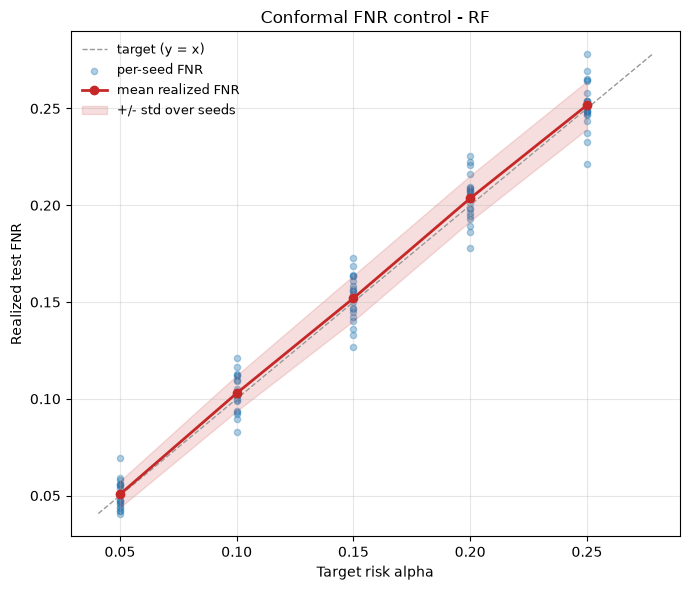

=== LGB ===
Pre-calibration metrics (mean over seeds):


,AUC,accuracy,precision,recall,f1,FNR,FPR
threshold 0.5 (pre),0.755,0.7,0.534,0.657,0.589,0.343,0.279


Post-calibration metrics per target alpha (mean over seeds):


,threshold,accuracy,precision,recall,f1,FNR,FPR
alpha,,,,,,,
0.05,0.235,0.478,0.381,0.949,0.543,0.051,0.752
0.10,0.293,0.540,0.408,0.898,0.561,0.102,0.634
0.15,0.339,0.587,0.433,0.848,0.574,0.152,0.539
0.20,0.382,0.623,0.457,0.797,0.580,0.203,0.461
0.25,0.425,0.653,0.481,0.745,0.584,0.255,0.392


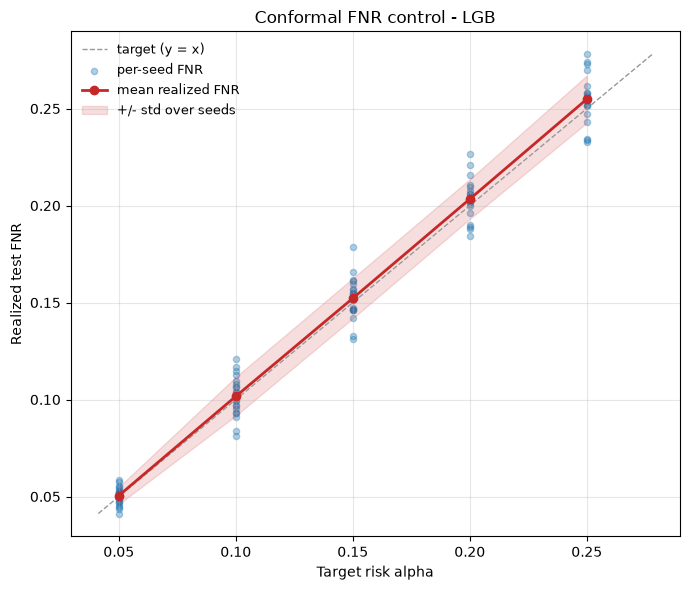

=== MLP ===
Pre-calibration metrics (mean over seeds):


,AUC,accuracy,precision,recall,f1,FNR,FPR
threshold 0.5 (pre),0.744,0.652,0.479,0.727,0.577,0.273,0.385


Post-calibration metrics per target alpha (mean over seeds):


,threshold,accuracy,precision,recall,f1,FNR,FPR
alpha,,,,,,,
0.05,0.329,0.457,0.371,0.951,0.534,0.049,0.783
0.10,0.381,0.530,0.402,0.898,0.556,0.102,0.650
0.15,0.423,0.582,0.430,0.849,0.571,0.151,0.548
0.20,0.455,0.614,0.449,0.797,0.575,0.203,0.475
0.25,0.486,0.640,0.468,0.746,0.575,0.254,0.412


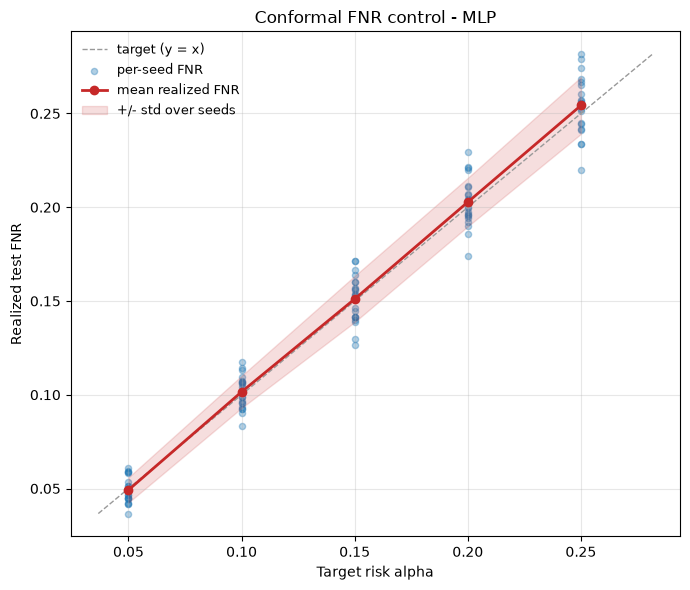

=== TABPFN ===
Pre-calibration metrics (mean over seeds):


,AUC,accuracy,precision,recall,f1,FNR,FPR
threshold 0.5 (pre),0.754,0.705,0.543,0.631,0.584,0.369,0.259


Post-calibration metrics per target alpha (mean over seeds):


,threshold,accuracy,precision,recall,f1,FNR,FPR
alpha,,,,,,,
0.05,0.235,0.472,0.378,0.949,0.541,0.051,0.760
0.10,0.288,0.539,0.407,0.897,0.560,0.103,0.636
0.15,0.332,0.587,0.433,0.848,0.573,0.152,0.540
0.20,0.368,0.621,0.455,0.801,0.580,0.199,0.467
0.25,0.407,0.653,0.480,0.750,0.586,0.250,0.394


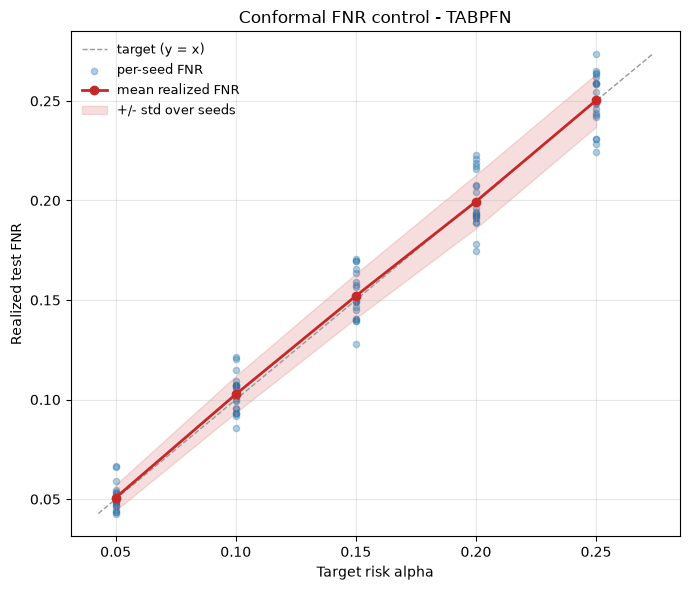

In [5]:
for model_type, df_conf in conformal_store.items():
    print(f"=== {model_type.upper()} ===")
    base, conf = crc_summary_tables(df_conf)
    print("Pre-calibration metrics (mean over seeds):")
    display(base)
    print("Post-calibration metrics per target alpha (mean over seeds):")
    display(conf)
    plot_conformal_fnr(df_conf, model_name=model_type)
    plt.show()

### Metric distributions across seeds

One figure per metric, models side by side. Within each model the first (grey) box
is the 0.5 threshold, then one box per target `alpha`, from lightest (0.05) to
darkest (0.25). Each box is the distribution of the metric over the seeds.

Recall is `1 - FNR`, so it is pinned by `alpha`; the other metrics show the price
of that recall, mostly through the false positives a lower threshold lets in.

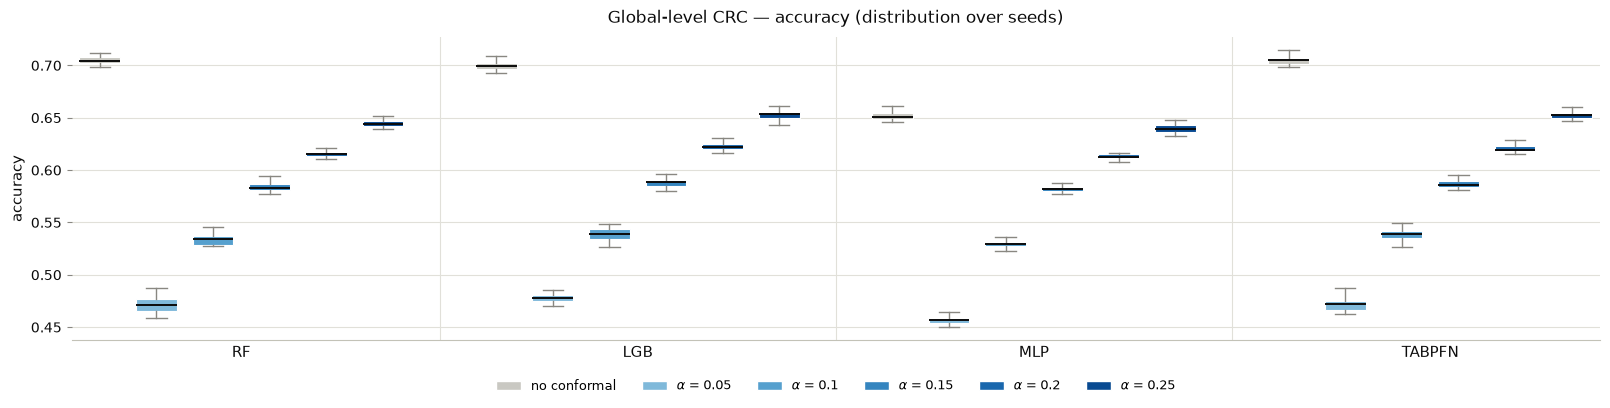

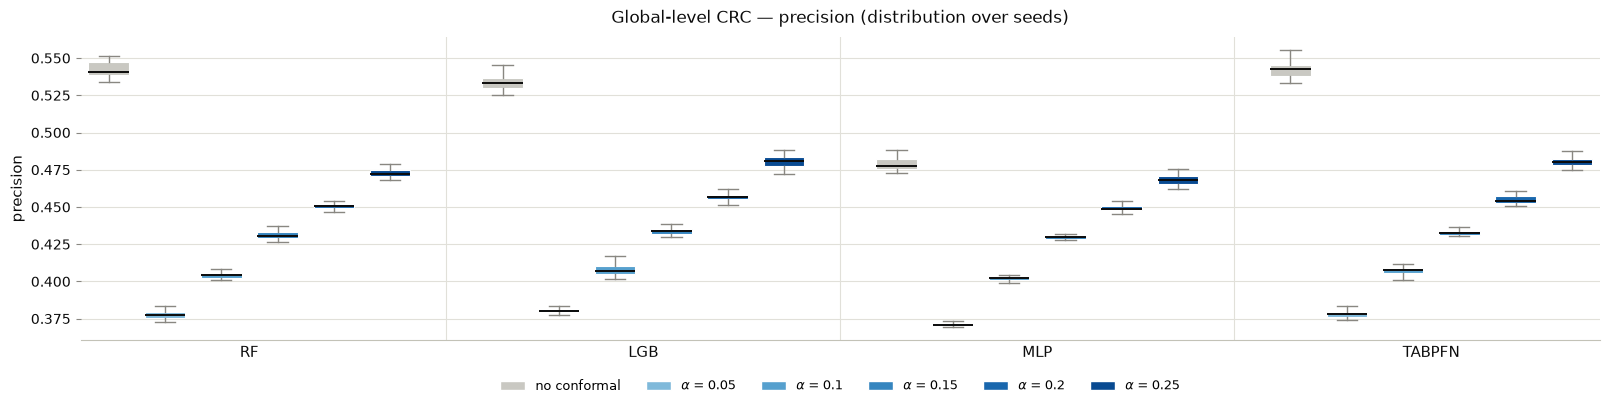

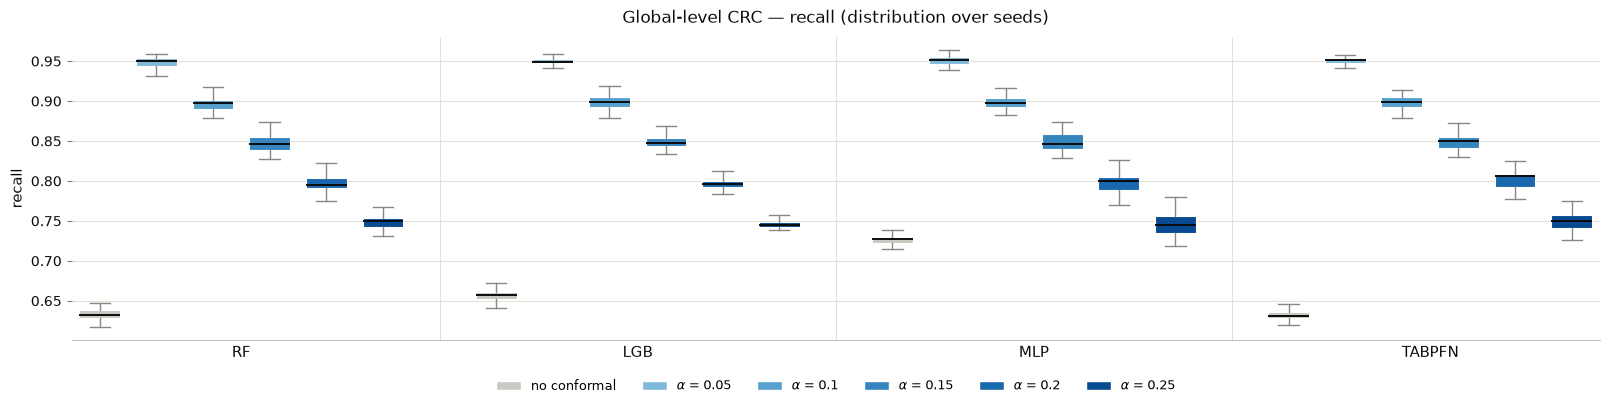

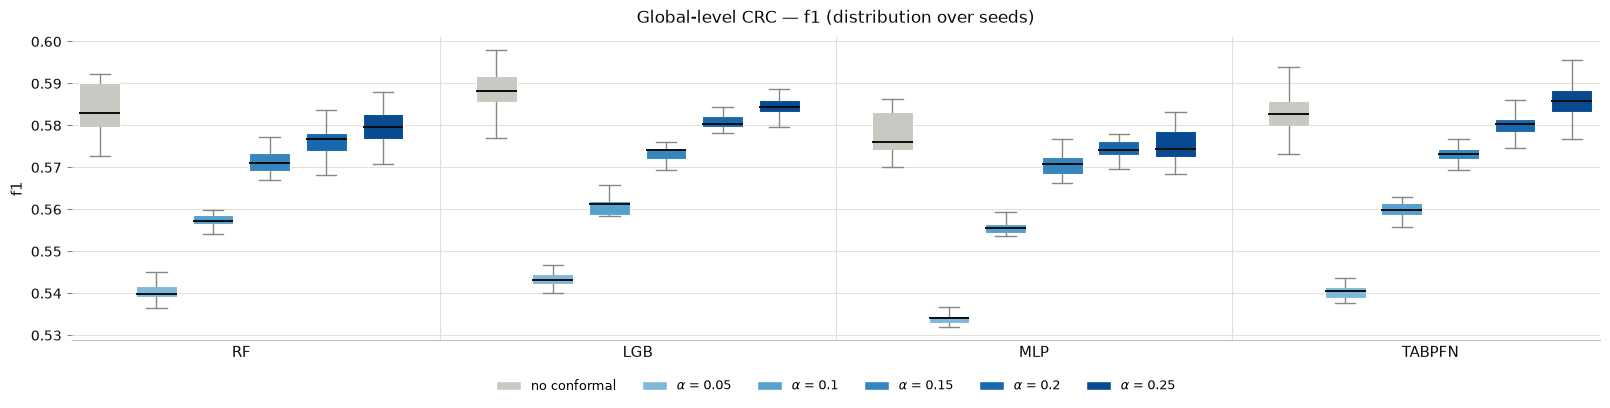

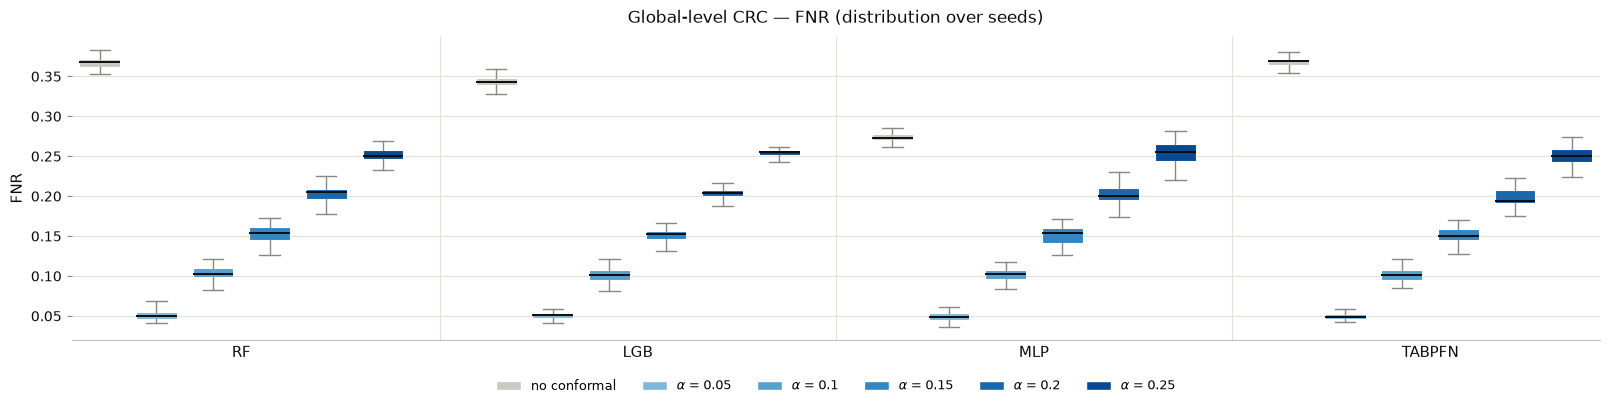

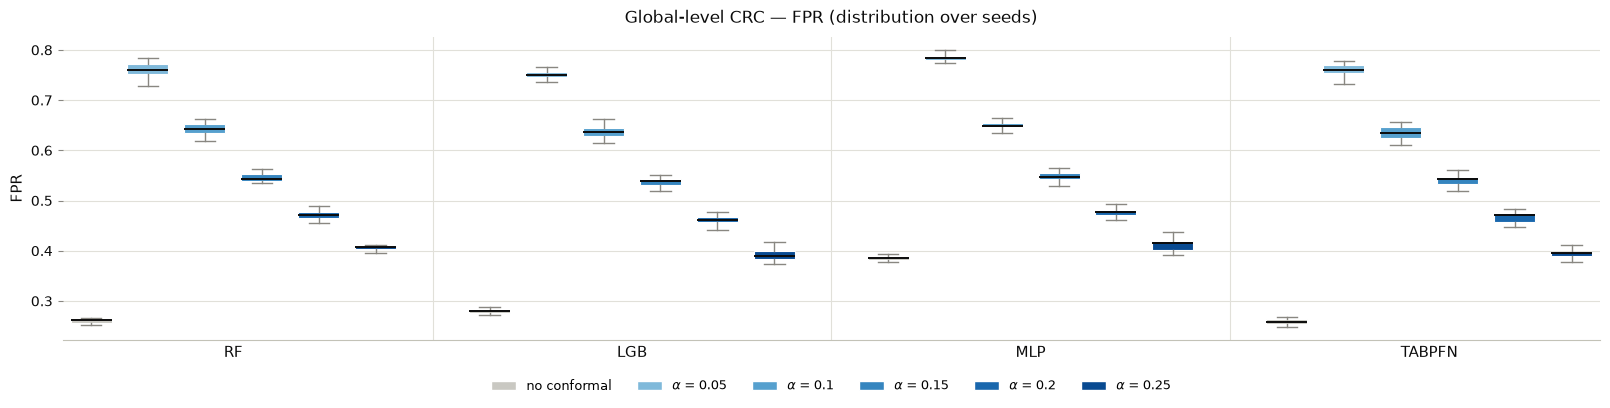

In [6]:
# Global-level CRC: per-metric boxplots over seeds (one representative frame per
# model; the pool is fixed so every model's frame carries the same seeds).
model_df = {}
for model_type, df_conf in conformal_store.items():
    model_df.setdefault(model_type, df_conf)
plot_crc_metric_boxplots(model_df)

---
## RQ2 — Subgroups under global-level CRC

The CRC guarantee is **marginal**: it holds on the pool as a whole, not within each
subgroup. Here the single global threshold is kept, and its realized FNR is
measured within each industry sector and each founding-year cohort.

The pool labels and groups are computed once and shared by every model. A group
whose calibration half holds fewer than `min_group` positives is flagged
`infeasible`.

In [7]:
# Group labels on the conformal pool (calibration + test rows, in pool order).
# Reused across models, since the pool is fixed.
pool_index   = X_cal_test.index
cohort_pool  = dataset.loc[pool_index, "YearFounded"].to_numpy()
labels_pool  = y_cal_test.to_numpy()

# Industry sector by name, read off the raw column (the features carry its
# train-fitted frequency encoding instead). The few rows without a sector form an
# "Unknown" group, flagged infeasible by min_group.
sector_pool = dataset.loc[pool_index, "PrimaryIndustrySector"].fillna("Unknown").to_numpy()

alphas = config["conformal"]["alpha"]
seeds  = config["conformal"]["seeds"]

model_color = assign_model_colors(list(conformal_pool_store))

# Compute the per-(model, dimension) tables once; keep the raw per-seed marginal
# AND conditional frames (the latter feeds RQ3). Sector first, then cohort.
subgroup_dims = [("Industry sector", sector_pool),
                 ("YearFounded cohort", cohort_pool)]
subgroup_tables = {}
subgroup_raw_marg = {}
subgroup_raw_cond = {}
for model_type, probs_pool in conformal_pool_store.items():
    for dim_name, groups in subgroup_dims:
        tab, raw_marg, raw_cond = fnr_by_group_table(
            probs_pool, labels_pool, groups, alphas, seeds, min_group=20)
        subgroup_tables[(model_type, dim_name)] = tab
        subgroup_raw_marg[(model_type, dim_name)] = raw_marg
        subgroup_raw_cond[(model_type, dim_name)] = raw_cond

### Industry sector

`FNR_marg` is the mean realized FNR of the group over the seeds; `FNR_marg - alpha`
is the gap above the target, blank when the group is at or below it. `n_pool` and
`n_pos_pool` are the size and the number of positives of the group in the whole
pool (calibration and test halves together); a group with no positives has an
undefined FNR, shown as `NaN`.

In the boxplots, one figure per `alpha`: groups on the x axis, one box per model,
each box the distribution of the realized FNR over the seeds. Boxes above the
dashed line are under-covered, boxes below it over-covered. Small groups have few
positives per test half, so expect taller boxes there.

=== RF — Industry sector ===


,Industry sector,alpha,FNR_marg,FNR_marg - alpha,n_pool,n_pos_pool
0,Business Products and Services (B2B),0.05,0.061,0.011,1912,496
1,Consumer Products and Services (B2C),0.05,0.067,0.017,2833,768
2,Energy,0.05,0.009,NaN,236,86
3,Financial Services,0.05,0.012,NaN,243,99
4,Healthcare,0.05,0.027,NaN,1369,623
5,Information Technology,0.05,0.053,0.003,5214,1781
6,Materials and Resources,0.05,0.048,NaN,196,76
7,Unknown,0.05,NaN,NaN,1,0
8,Business Products and Services (B2B),0.10,0.152,0.052,1912,496
9,Consumer Products and Services (B2C),0.10,0.127,0.027,2833,768


=== LGB — Industry sector ===


,Industry sector,alpha,FNR_marg,FNR_marg - alpha,n_pool,n_pos_pool
0,Business Products and Services (B2B),0.05,0.062,0.012,1912,496
1,Consumer Products and Services (B2C),0.05,0.069,0.019,2833,768
2,Energy,0.05,0.009,NaN,236,86
3,Financial Services,0.05,0.012,NaN,243,99
4,Healthcare,0.05,0.026,NaN,1369,623
5,Information Technology,0.05,0.052,0.002,5214,1781
6,Materials and Resources,0.05,0.048,NaN,196,76
7,Unknown,0.05,NaN,NaN,1,0
8,Business Products and Services (B2B),0.10,0.171,0.071,1912,496
9,Consumer Products and Services (B2C),0.10,0.129,0.029,2833,768


=== MLP — Industry sector ===


,Industry sector,alpha,FNR_marg,FNR_marg - alpha,n_pool,n_pos_pool
0,Business Products and Services (B2B),0.05,0.051,0.001,1912,496
1,Consumer Products and Services (B2C),0.05,0.056,0.006,2833,768
2,Energy,0.05,0.009,NaN,236,86
3,Financial Services,0.05,0.012,NaN,243,99
4,Healthcare,0.05,0.031,NaN,1369,623
5,Information Technology,0.05,0.057,0.007,5214,1781
6,Materials and Resources,0.05,0.032,NaN,196,76
7,Unknown,0.05,NaN,NaN,1,0
8,Business Products and Services (B2B),0.10,0.139,0.039,1912,496
9,Consumer Products and Services (B2C),0.10,0.115,0.015,2833,768


=== TABPFN — Industry sector ===


,Industry sector,alpha,FNR_marg,FNR_marg - alpha,n_pool,n_pos_pool
0,Business Products and Services (B2B),0.05,0.056,0.006,1912,496
1,Consumer Products and Services (B2C),0.05,0.076,0.026,2833,768
2,Energy,0.05,0.009,NaN,236,86
3,Financial Services,0.05,0.002,NaN,243,99
4,Healthcare,0.05,0.022,NaN,1369,623
5,Information Technology,0.05,0.053,0.003,5214,1781
6,Materials and Resources,0.05,0.042,NaN,196,76
7,Unknown,0.05,NaN,NaN,1,0
8,Business Products and Services (B2B),0.10,0.133,0.033,1912,496
9,Consumer Products and Services (B2C),0.10,0.142,0.042,2833,768


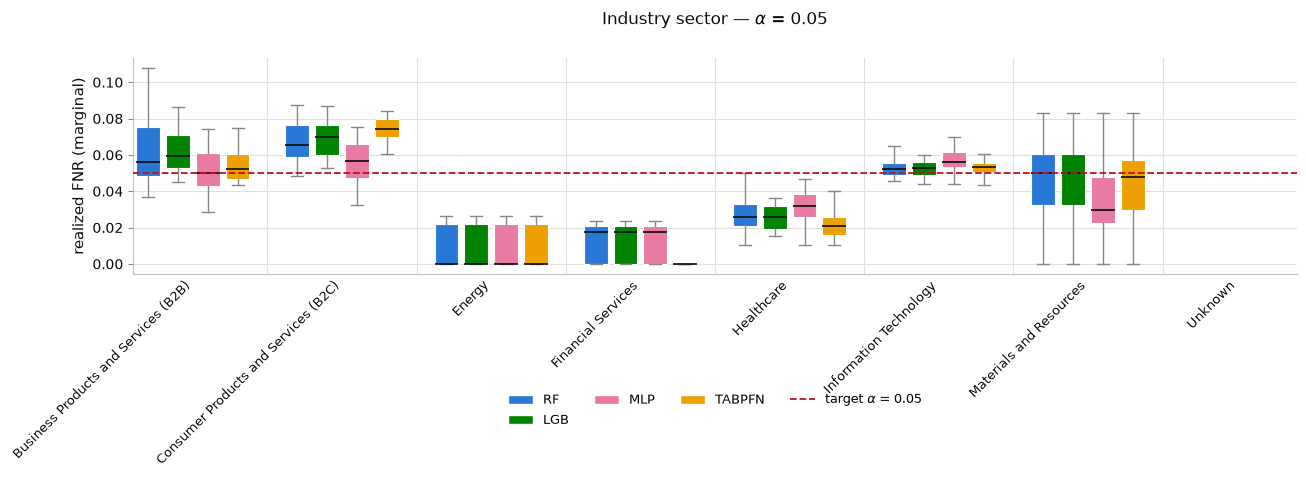

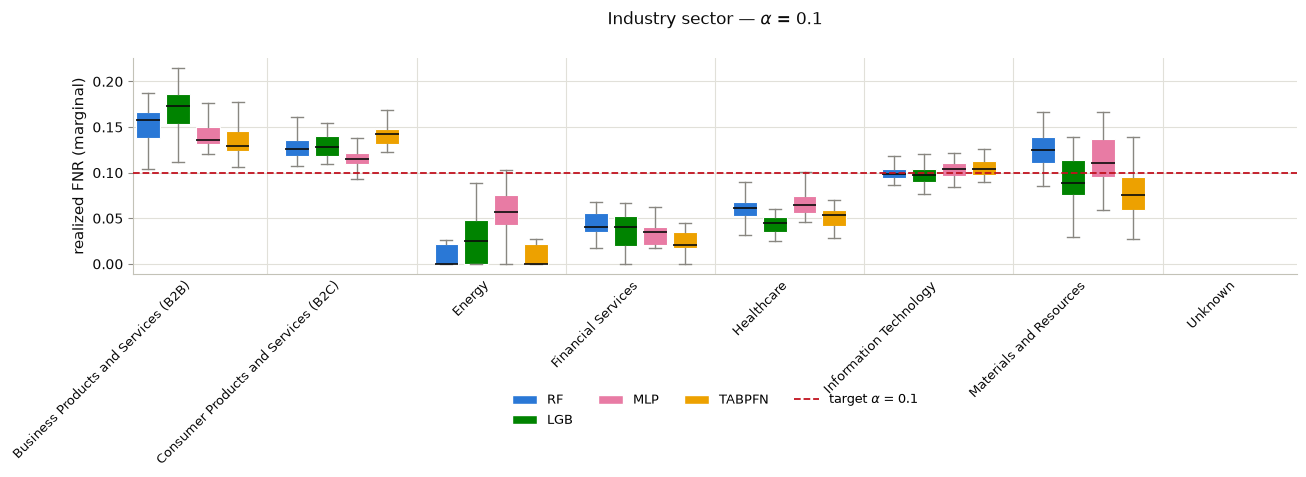

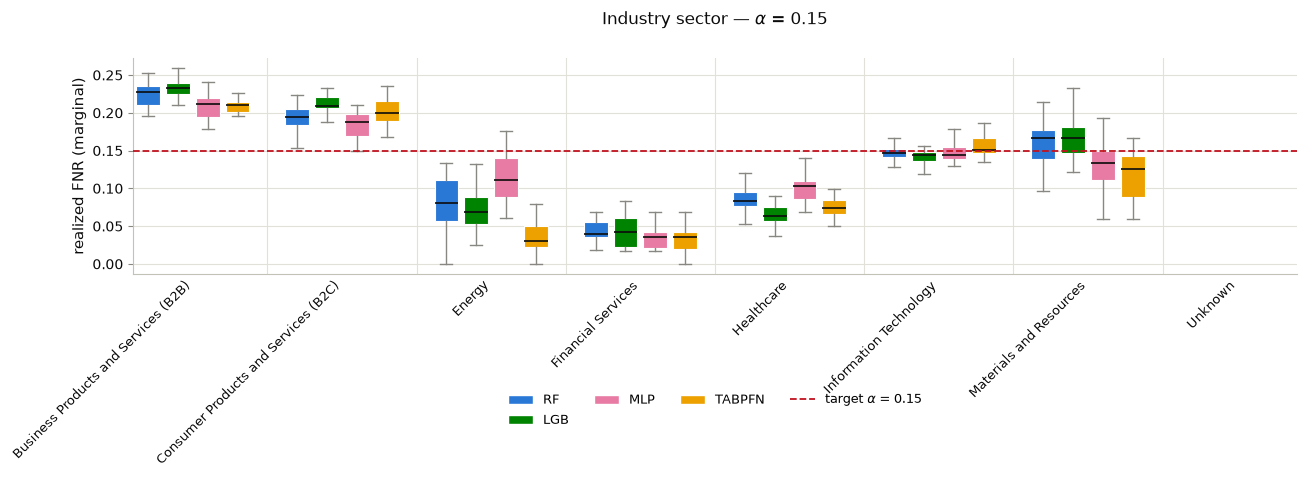

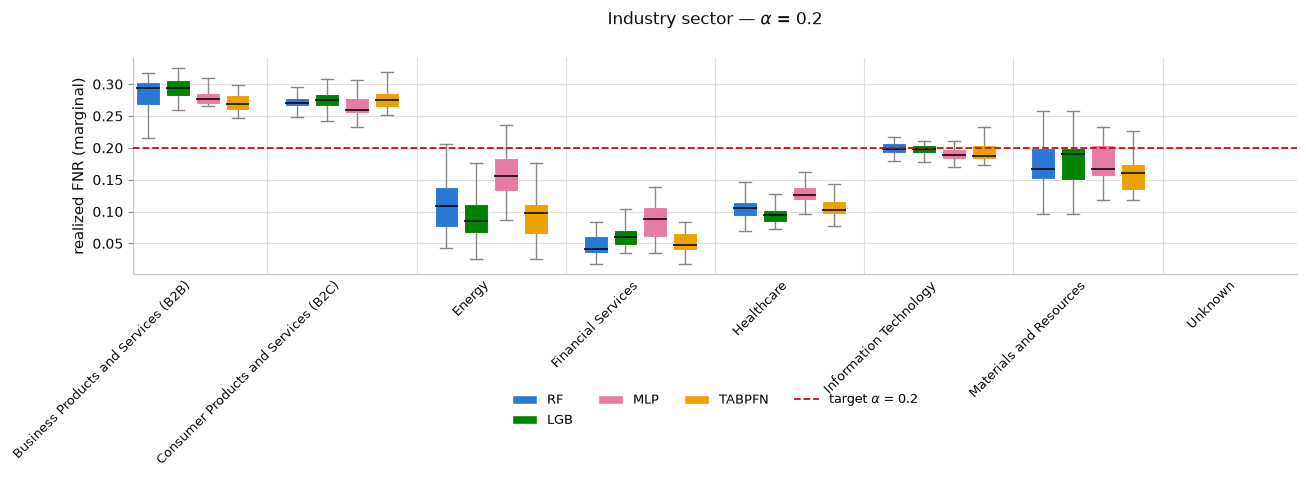

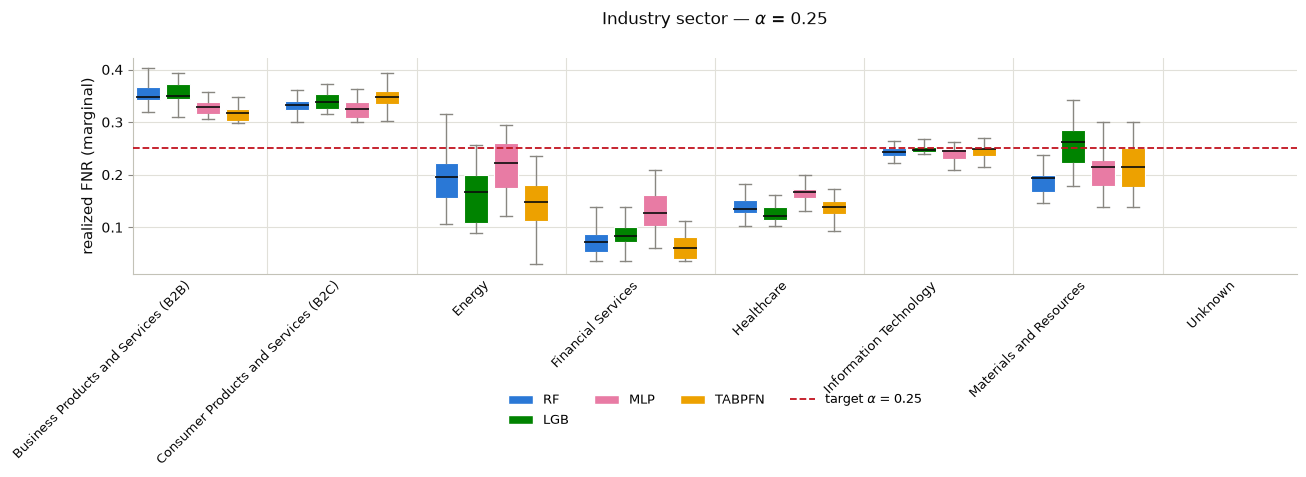

In [8]:
# Industry sector — table then grouped boxplot (models side by side, one figure
# per alpha).
marg_cols = ["group", "alpha", "FNR_marg", "FNR_marg - alpha",
             "n_pool", "n_pos_pool"]
dim_name = "Industry sector"
for (model_type, d), tab in subgroup_tables.items():
    if d != dim_name:
        continue
    print(f"=== {model_type.upper()} — {dim_name} ===")
    display(tab[marg_cols].rename(columns={"group": dim_name}))

sector_raw = {m: raw for (m, d), raw in subgroup_raw_marg.items() if d == dim_name}
plot_fnr_by_group_boxplots(sector_raw, dim_name, model_color,
                           ylabel="realized FNR (marginal)")

### Founding-year cohort

Same table and boxplots, with the cohorts (`YearFounded`) as groups. The line plot
adds a per-model view across the cohorts: mean realized FNR over the seeds,
± 1 standard deviation band, and the target `alpha` as a dashed line.

=== RF — YearFounded cohort ===


,YearFounded cohort,alpha,FNR_marg,FNR_marg - alpha,n_pool,n_pos_pool
0,2008,0.05,0.028,NaN,65,29
1,2009,0.05,0.019,NaN,238,99
2,2010,0.05,0.016,NaN,701,253
3,2011,0.05,0.056,0.006,999,308
4,2012,0.05,0.037,NaN,1313,404
5,2013,0.05,0.065,0.015,1657,514
6,2014,0.05,0.048,NaN,1923,663
7,2015,0.05,0.058,0.008,2146,719
8,2016,0.05,0.050,NaN,1794,602
9,2017,0.05,0.068,0.018,1168,338


=== LGB — YearFounded cohort ===


,YearFounded cohort,alpha,FNR_marg,FNR_marg - alpha,n_pool,n_pos_pool
0,2008,0.05,0.028,NaN,65,29
1,2009,0.05,0.027,NaN,238,99
2,2010,0.05,0.041,NaN,701,253
3,2011,0.05,0.052,0.002,999,308
4,2012,0.05,0.034,NaN,1313,404
5,2013,0.05,0.059,0.009,1657,514
6,2014,0.05,0.043,NaN,1923,663
7,2015,0.05,0.058,0.008,2146,719
8,2016,0.05,0.043,NaN,1794,602
9,2017,0.05,0.085,0.035,1168,338


=== MLP — YearFounded cohort ===


,YearFounded cohort,alpha,FNR_marg,FNR_marg - alpha,n_pool,n_pos_pool
0,2008,0.05,0.000,NaN,65,29
1,2009,0.05,0.028,NaN,238,99
2,2010,0.05,0.035,NaN,701,253
3,2011,0.05,0.055,0.005,999,308
4,2012,0.05,0.039,NaN,1313,404
5,2013,0.05,0.060,0.010,1657,514
6,2014,0.05,0.043,NaN,1923,663
7,2015,0.05,0.047,NaN,2146,719
8,2016,0.05,0.057,0.007,1794,602
9,2017,0.05,0.064,0.014,1168,338


=== TABPFN — YearFounded cohort ===


,YearFounded cohort,alpha,FNR_marg,FNR_marg - alpha,n_pool,n_pos_pool
0,2008,0.05,0.000,NaN,65,29
1,2009,0.05,0.027,NaN,238,99
2,2010,0.05,0.043,NaN,701,253
3,2011,0.05,0.056,0.006,999,308
4,2012,0.05,0.023,NaN,1313,404
5,2013,0.05,0.057,0.007,1657,514
6,2014,0.05,0.040,NaN,1923,663
7,2015,0.05,0.056,0.006,2146,719
8,2016,0.05,0.057,0.007,1794,602
9,2017,0.05,0.084,0.034,1168,338


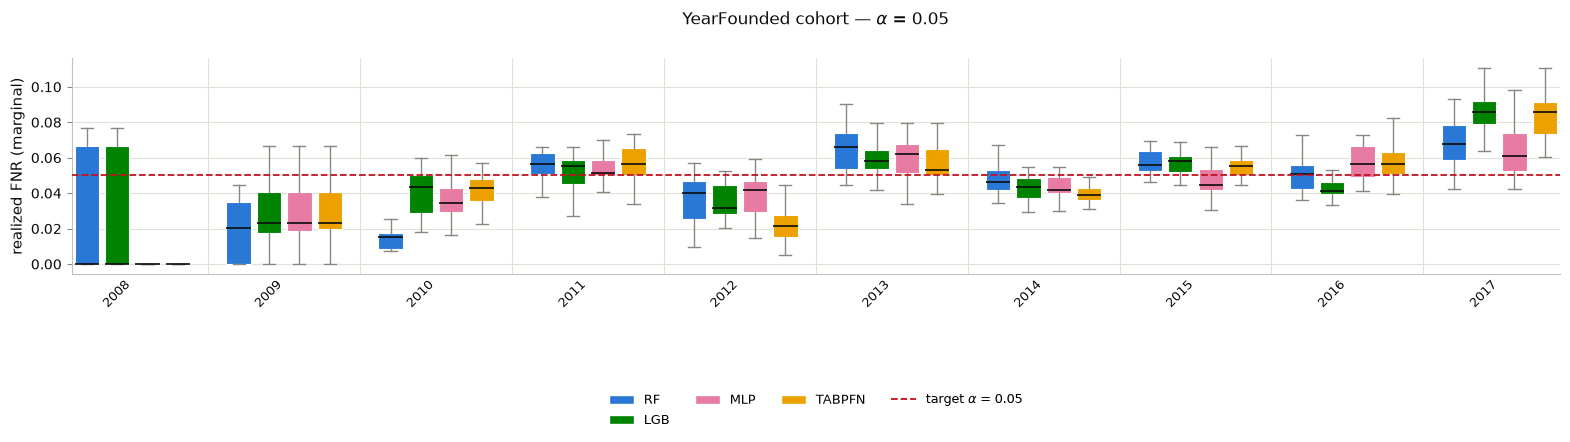

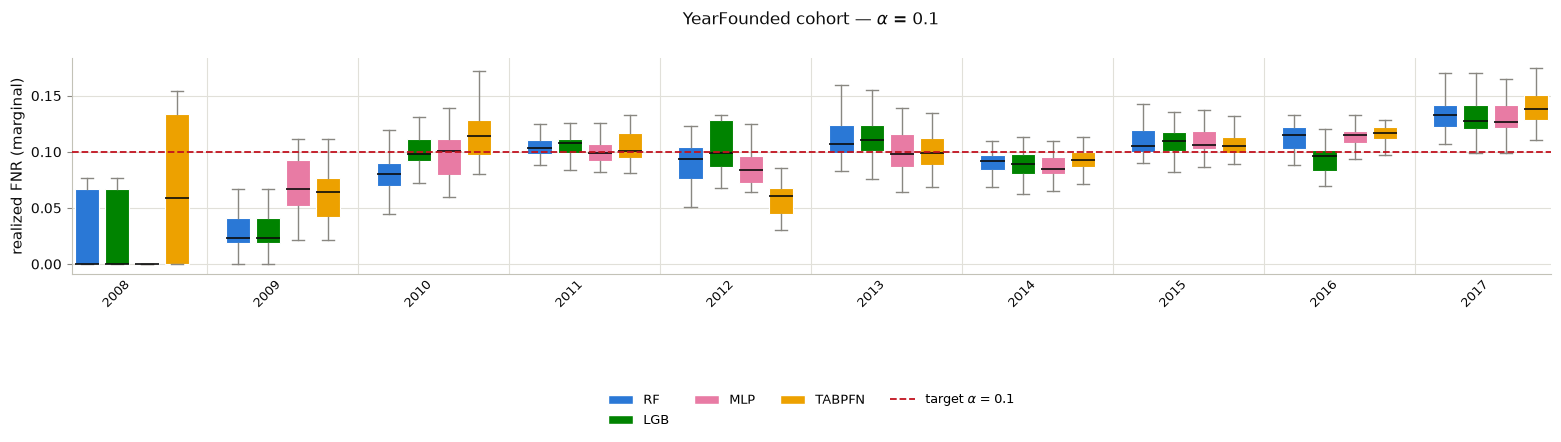

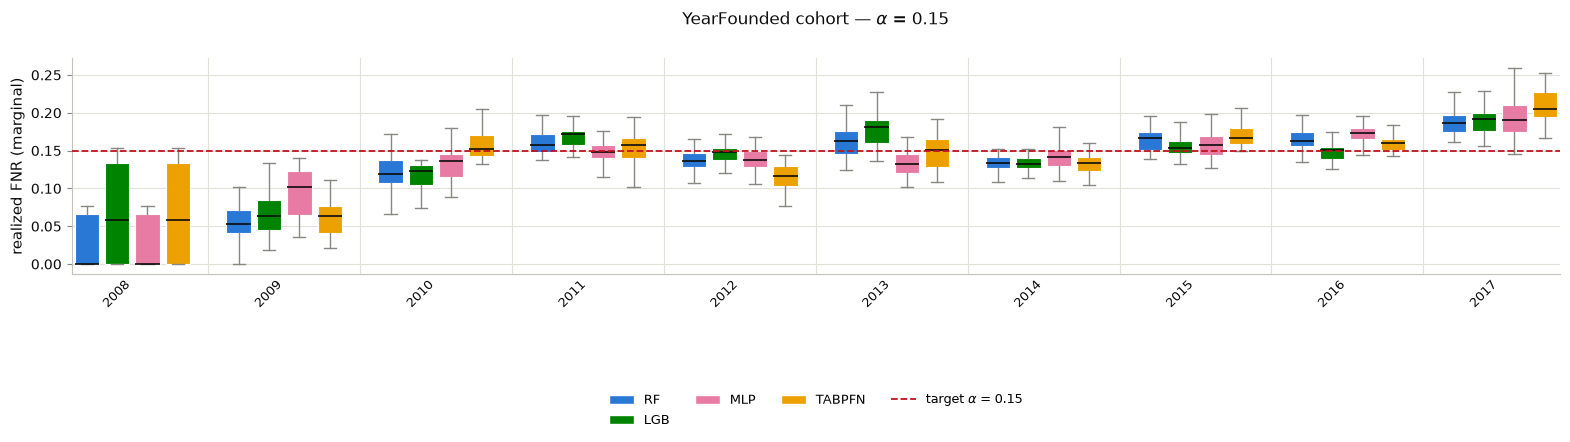

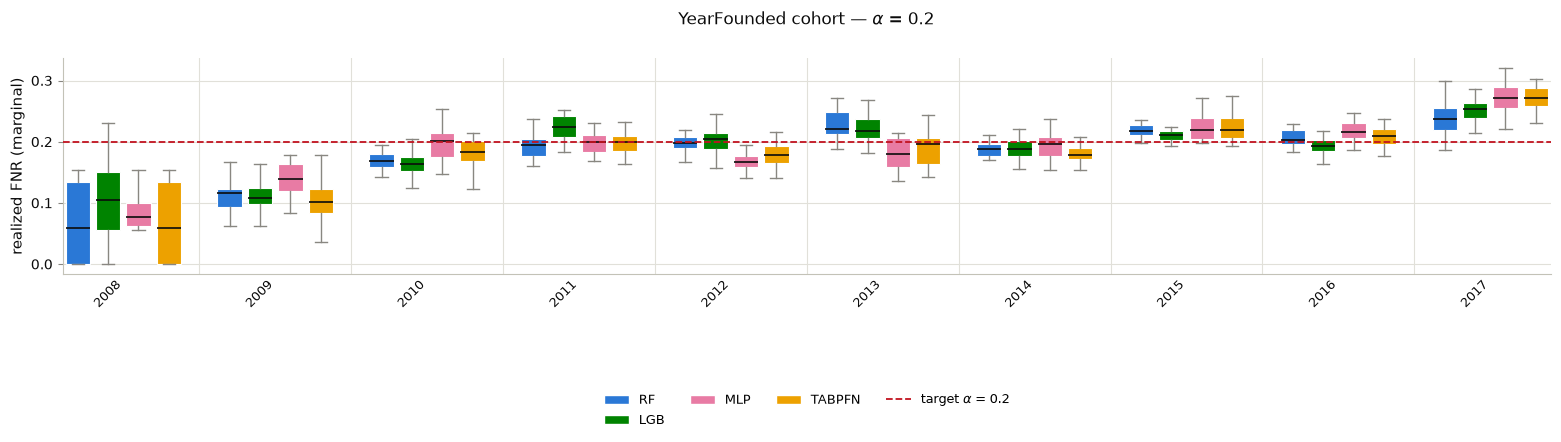

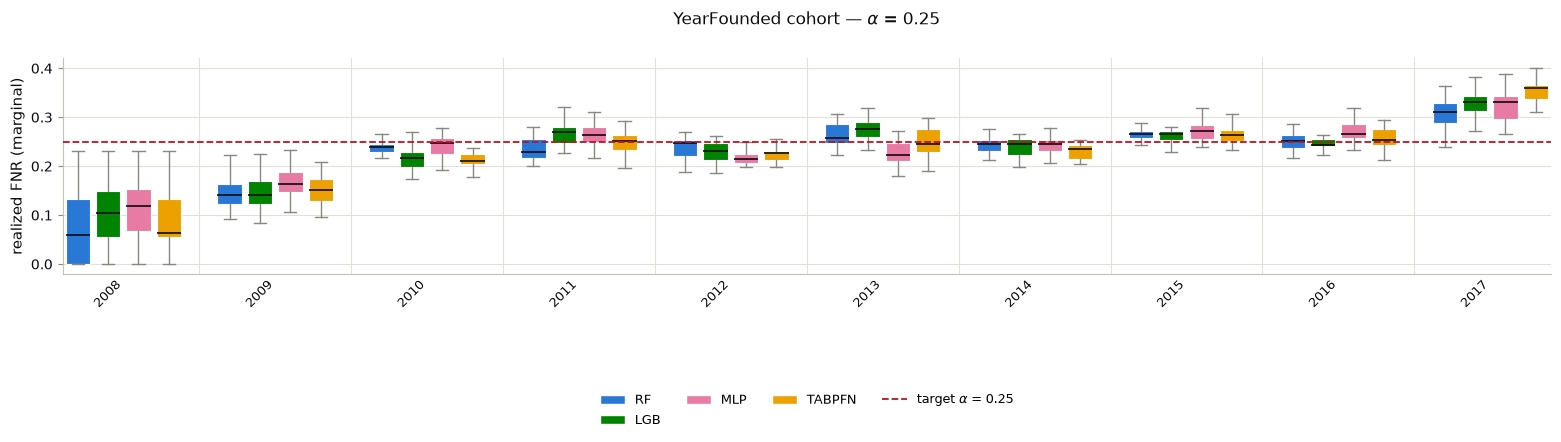

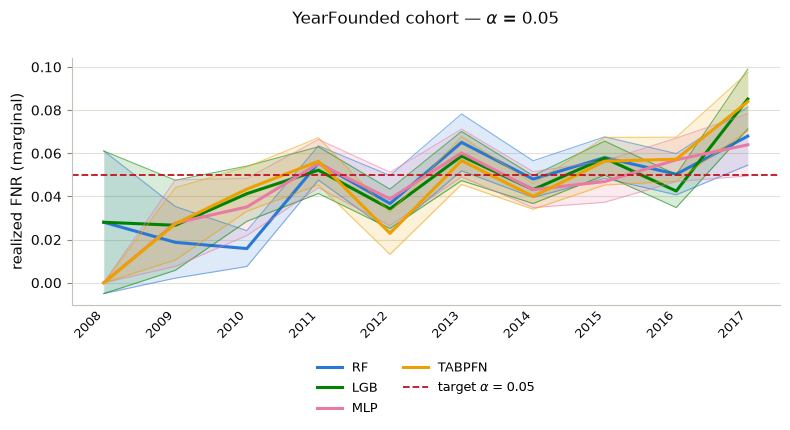

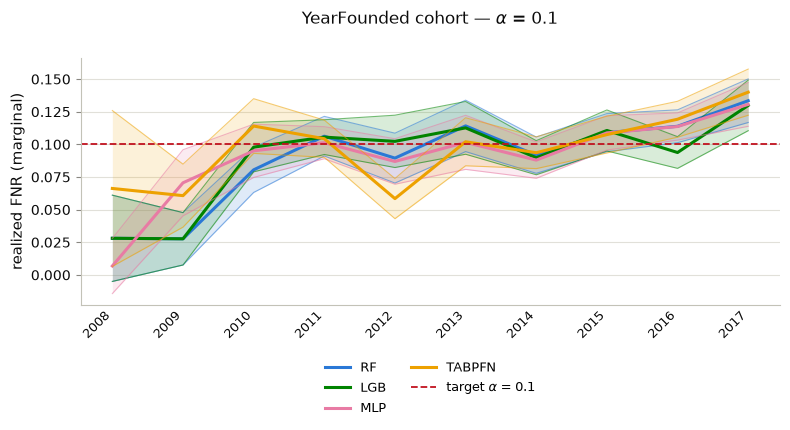

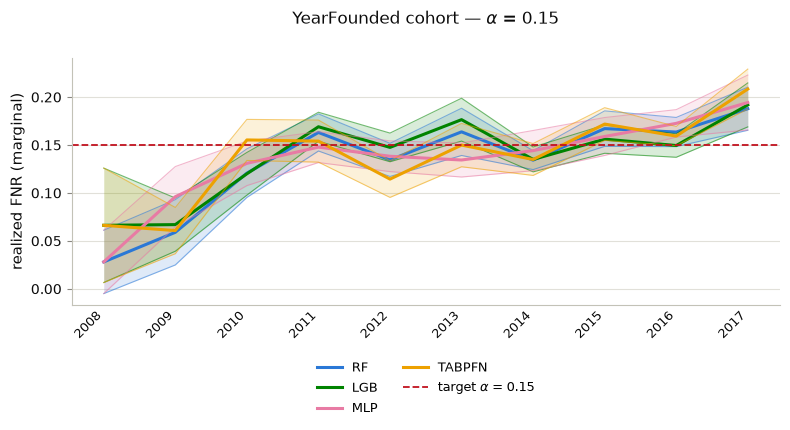

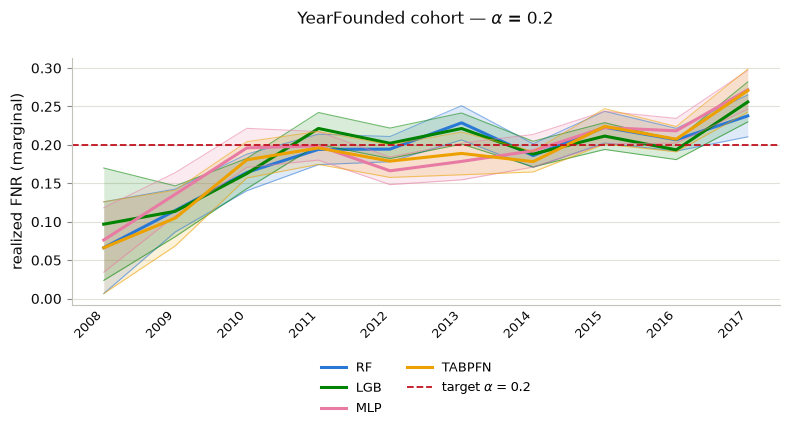

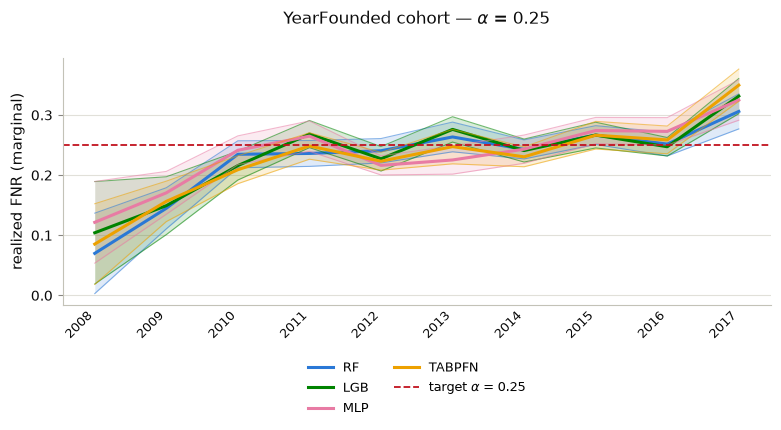

In [9]:
# YearFounded cohort — table, grouped boxplot, then per-model line plot.
marg_cols = ["group", "alpha", "FNR_marg", "FNR_marg - alpha",
             "n_pool", "n_pos_pool"]
dim_name = "YearFounded cohort"
for (model_type, d), tab in subgroup_tables.items():
    if d != dim_name:
        continue
    print(f"=== {model_type.upper()} — {dim_name} ===")
    display(tab[marg_cols].rename(columns={"group": dim_name}))

cohort_raw = {m: raw for (m, d), raw in subgroup_raw_marg.items() if d == dim_name}
plot_fnr_by_group_boxplots(cohort_raw, dim_name, model_color,
                           ylabel="realized FNR (marginal)")
plot_fnr_by_group_lines(cohort_raw, dim_name, model_color,
                        ylabel="realized FNR (marginal)")

---
## RQ3 — Group-level CRC

Group-level (Mondrian) CRC calibrates a **separate threshold per subgroup**, on
that group's calibration rows, and applies it to the same group in the test half.
The guarantee then holds within each group instead of only on average. Both
groupings of RQ2 are used, sector and cohort.

An `infeasible` group does not have enough calibration positives for a per-group
threshold to mean anything; it falls back to the global threshold and stays
flagged in the tables.

### Global metrics under group-level calibration

The per-group thresholds are applied, and the metrics are measured on the whole
test half, as in RQ1, so the tables and boxplots read the same way. The
`threshold` column is empty: there is no single threshold any more.

In [10]:
# Group-calibrated global CRC per (model, grouping). Reuses the same pool.
group_cal_store = {}
for model_type, probs_pool in conformal_pool_store.items():
    for dim_name, groups in subgroup_dims:
        group_cal_store[(model_type, dim_name)] = run_conformal_fnr_group_calibrated(
            probs_pool, labels_pool, groups, alphas, seeds, min_group=20)

In [11]:
# Summary tables (pre/post) per model, one block per grouping.
for dim_name, _ in subgroup_dims:
    print(f"################  Group-level CRC calibrated by {dim_name}  ################")
    for (model_type, d), df_gc in group_cal_store.items():
        if d != dim_name:
            continue
        print(f"=== {model_type.upper()} — calibrated by {dim_name} ===")
        base, conf = crc_summary_tables(df_gc)
        print("Pre-calibration metrics (mean over seeds):")
        display(base)
        print("Post-calibration metrics per target alpha (mean over seeds):")
        display(conf)

################  Group-level CRC calibrated by Industry sector  ################
=== RF — calibrated by Industry sector ===
Pre-calibration metrics (mean over seeds):


,AUC,accuracy,precision,recall,f1,FNR,FPR
threshold 0.5 (pre),0.751,0.705,0.542,0.632,0.584,0.368,0.26


Post-calibration metrics per target alpha (mean over seeds):


,threshold,accuracy,precision,recall,f1,FNR,FPR
alpha,,,,,,,
0.05,NaN,0.463,0.374,0.951,0.537,0.049,0.775
0.10,NaN,0.530,0.402,0.900,0.556,0.100,0.650
0.15,NaN,0.575,0.425,0.850,0.567,0.150,0.559
0.20,NaN,0.611,0.447,0.799,0.574,0.201,0.480
0.25,NaN,0.638,0.467,0.750,0.576,0.250,0.416


=== LGB — calibrated by Industry sector ===
Pre-calibration metrics (mean over seeds):


...

,threshold,accuracy,precision,recall,f1,FNR,FPR
alpha,,,,,,,
0.05,NaN,0.452,0.369,0.952,0.532,0.048,0.791
0.10,NaN,0.523,0.399,0.902,0.553,0.098,0.661
0.15,NaN,0.581,0.429,0.850,0.570,0.150,0.550
0.20,NaN,0.611,0.447,0.800,0.574,0.200,0.481
0.25,NaN,0.640,0.469,0.749,0.577,0.251,0.413


=== TABPFN — calibrated by YearFounded cohort ===
Pre-calibration metrics (mean over seeds):


,AUC,accuracy,precision,recall,f1,FNR,FPR
threshold 0.5 (pre),0.754,0.705,0.543,0.631,0.584,0.369,0.259


Post-calibration metrics per target alpha (mean over seeds):


,threshold,accuracy,precision,recall,f1,FNR,FPR
alpha,,,,,,,
0.05,NaN,0.464,0.374,0.952,0.537,0.048,0.774
0.10,NaN,0.534,0.405,0.900,0.558,0.100,0.645
0.15,NaN,0.579,0.428,0.850,0.569,0.150,0.553
0.20,NaN,0.618,0.453,0.802,0.579,0.198,0.471
0.25,NaN,0.649,0.477,0.752,0.583,0.248,0.401


################  Group-level CRC calibrated by Industry sector  ################


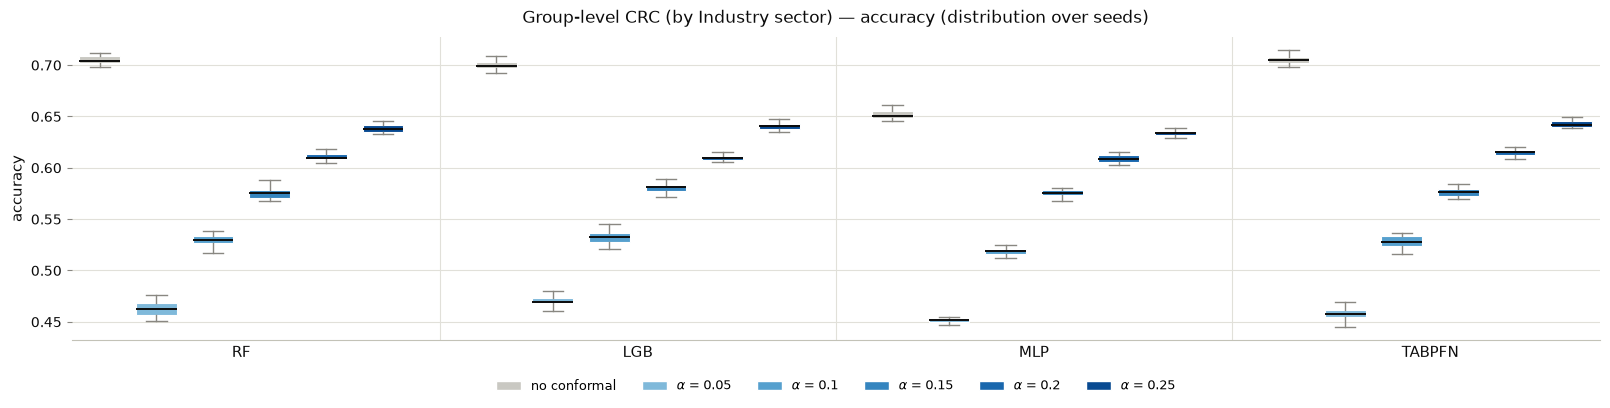

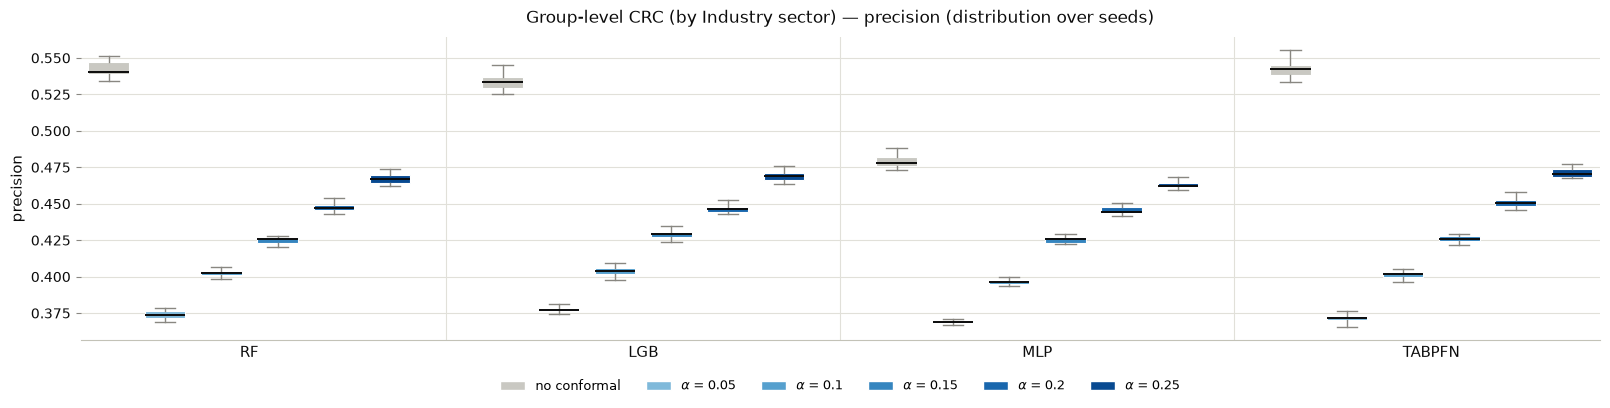

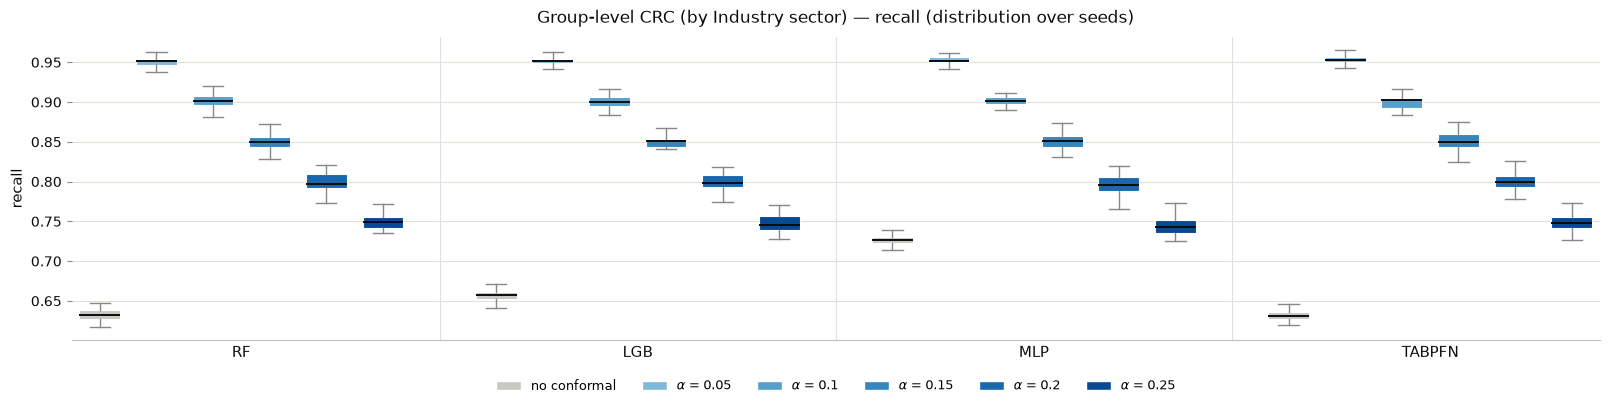

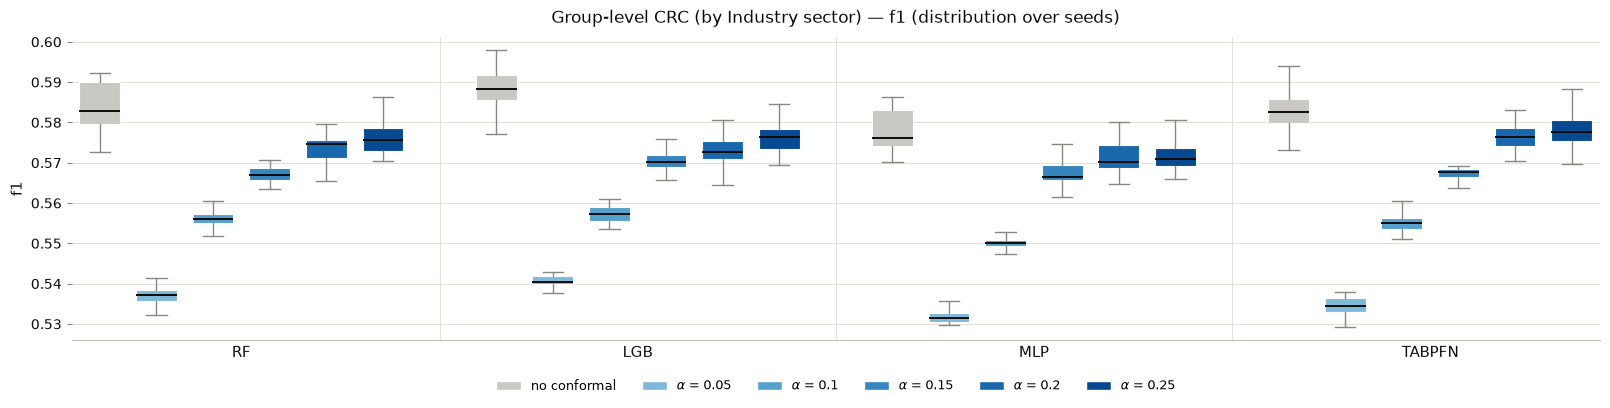

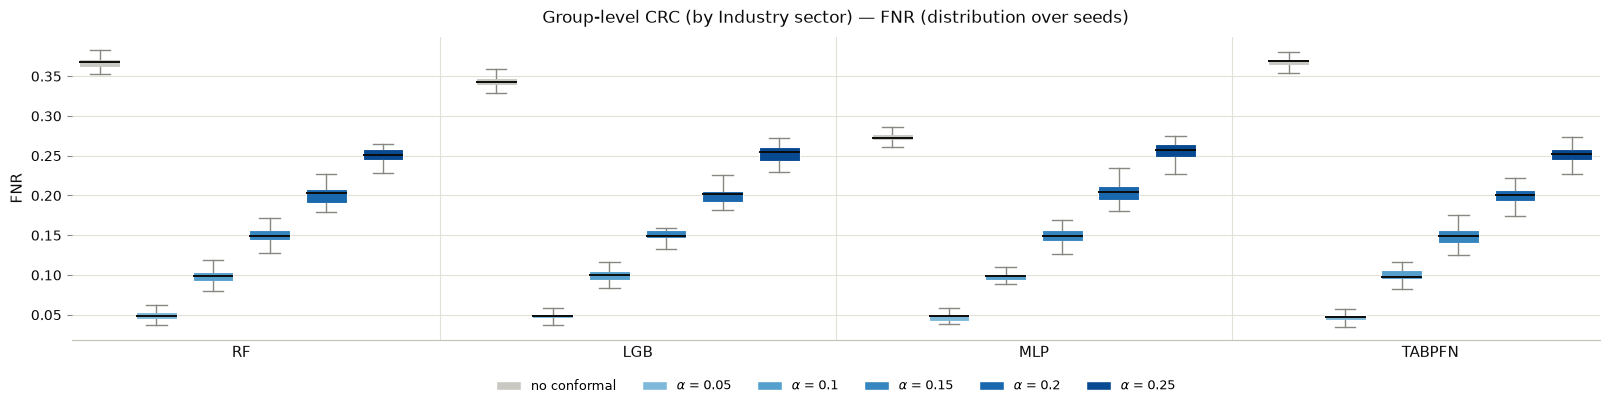

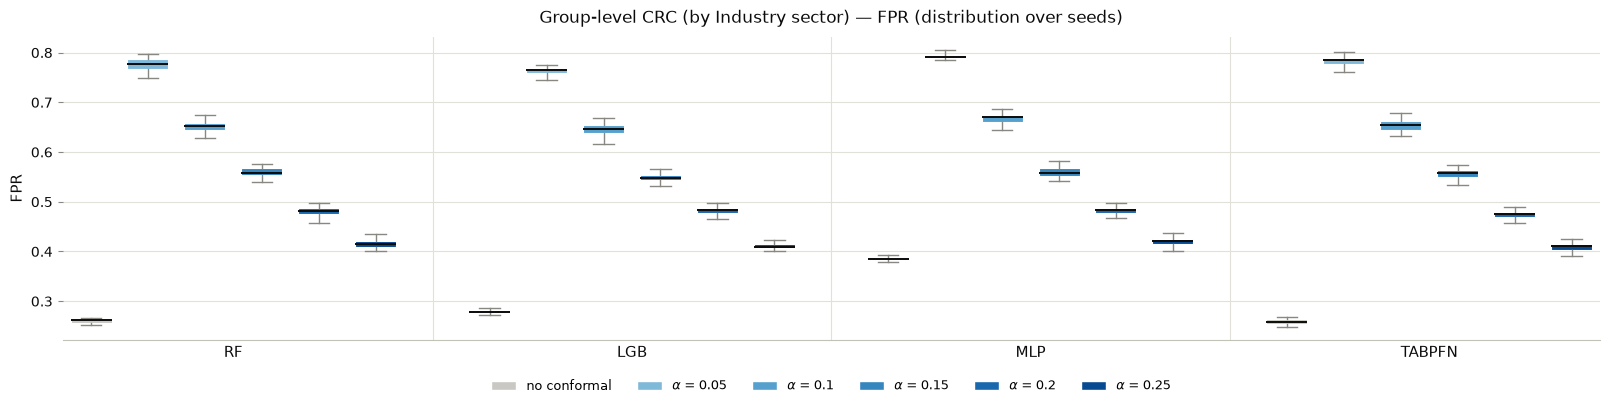

################  Group-level CRC calibrated by YearFounded cohort  ################


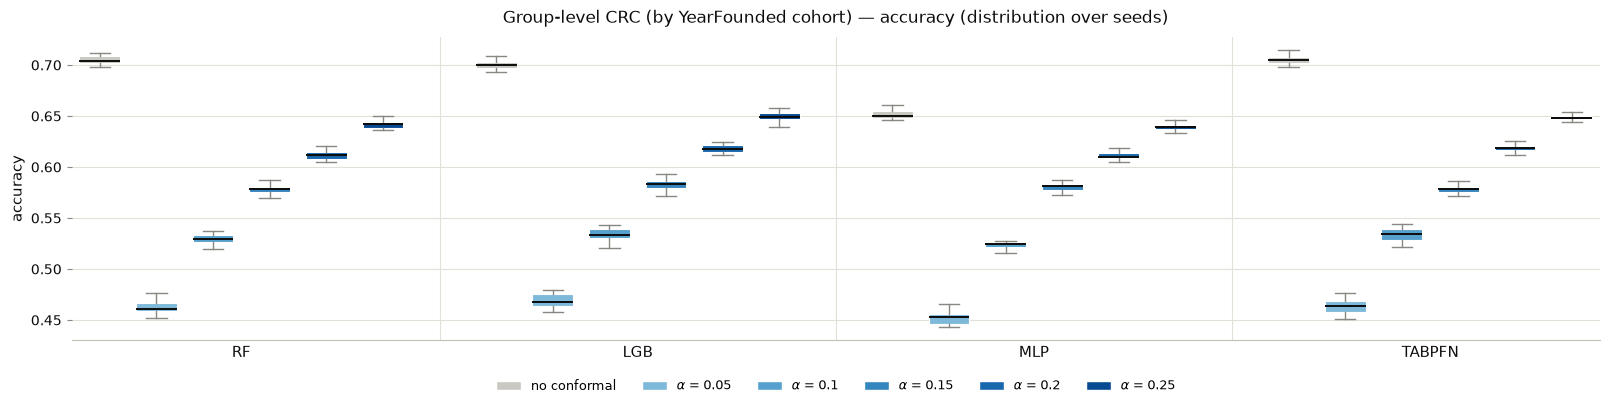

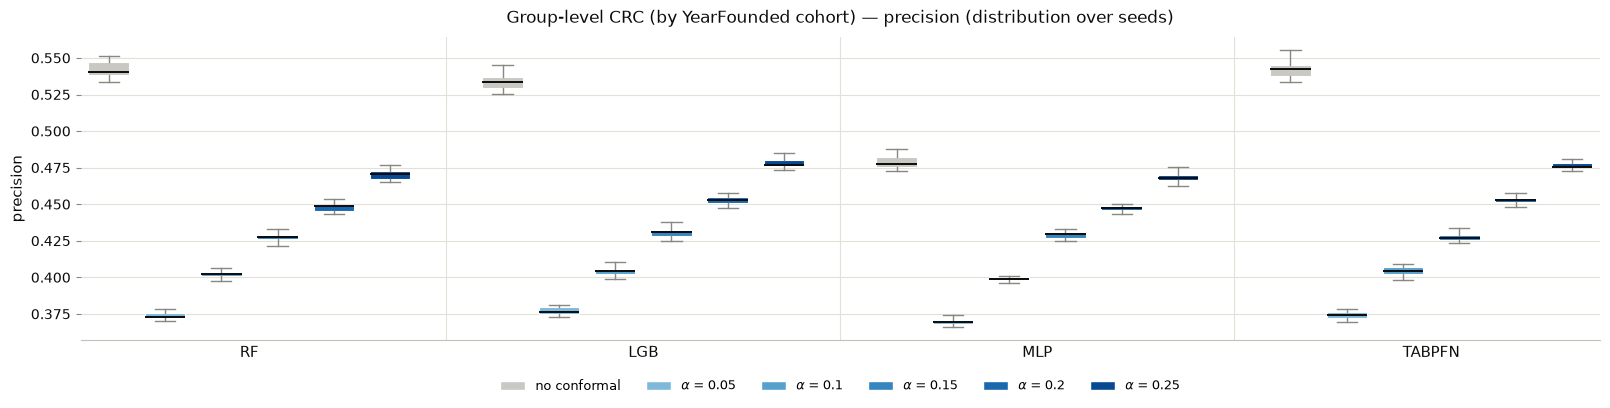

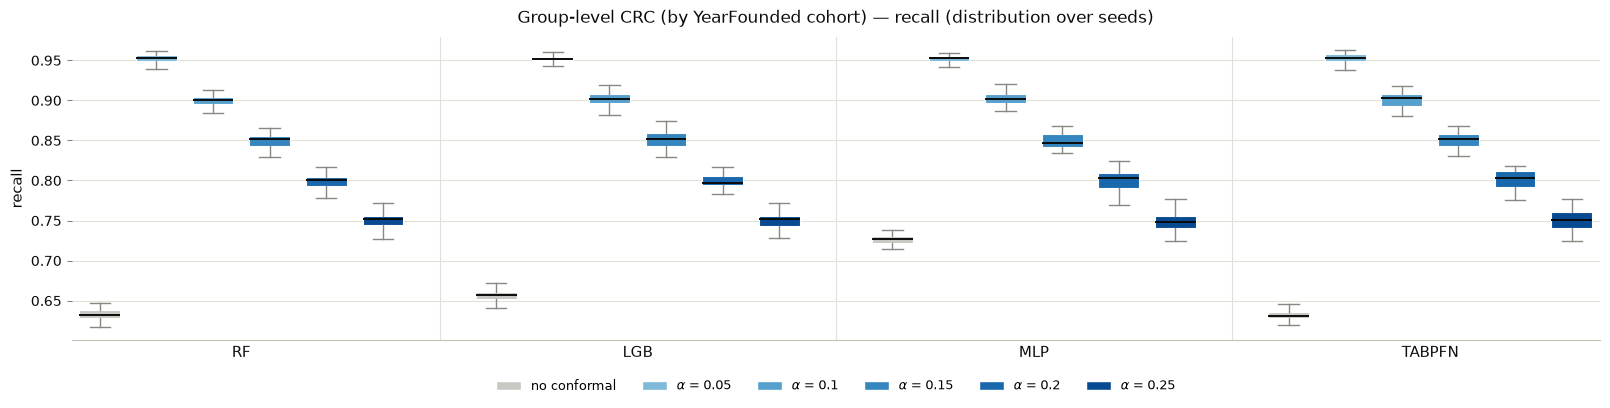

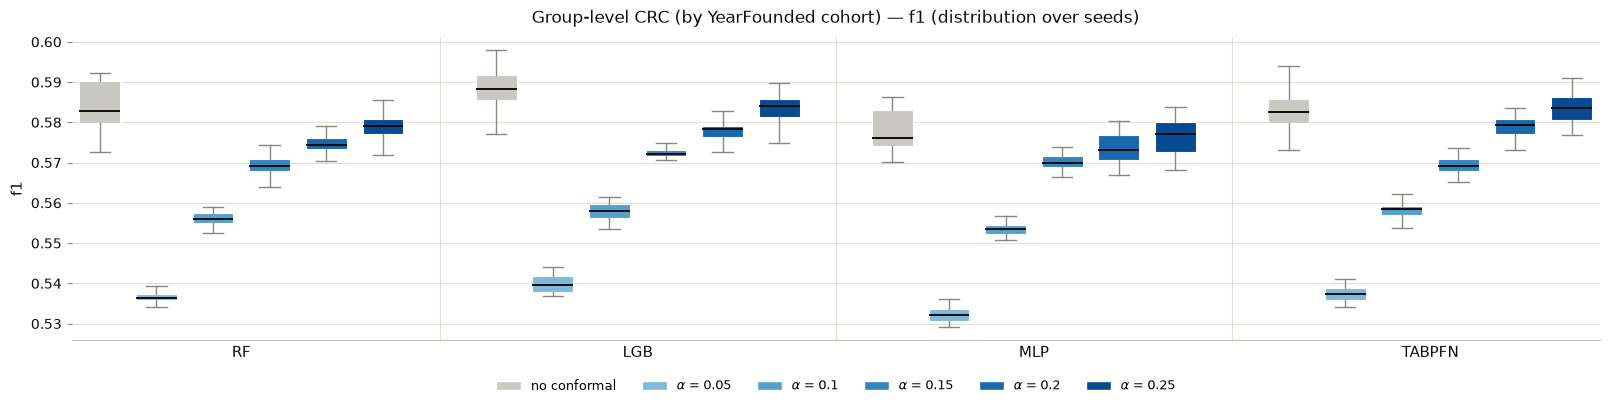

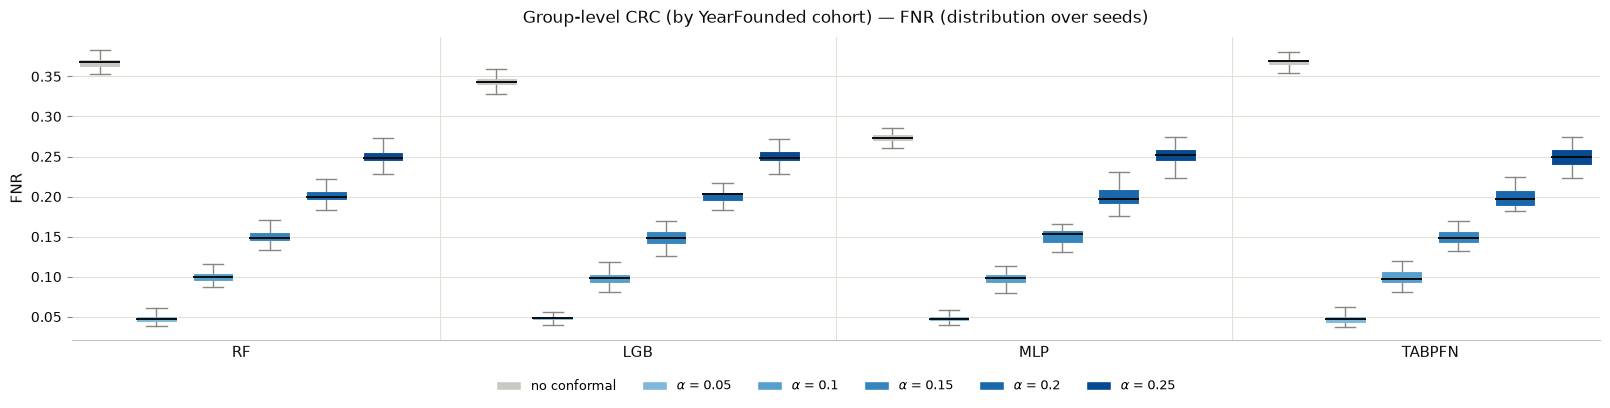

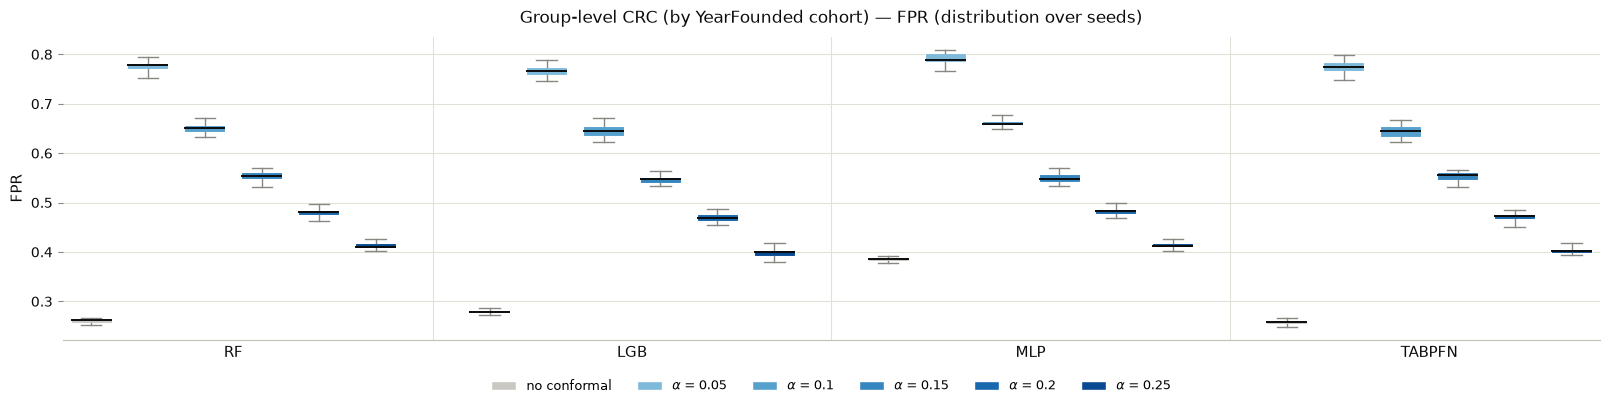

In [12]:
# Per-metric global boxplots, one set of figures per grouping.
for dim_name, _ in subgroup_dims:
    print(f"################  Group-level CRC calibrated by {dim_name}  ################")
    model_df = {m: df for (m, d), df in group_cal_store.items() if d == dim_name}
    plot_crc_metric_boxplots(model_df,
                             title_prefix=f"Group-level CRC (by {dim_name})")

### Mondrian minus standard CRC

The difference, model by model and `alpha` by `alpha`, between the metrics of the
group-level version and those of the global one of RQ1: Δ = Mondrian − standard,
means over seeds. Both versions run on the same pool and the same seeds, so the
rows are paired.

For FNR and FPR a positive Δ means more errors under Mondrian; for accuracy,
precision, recall and F1 it means Mondrian does better. Both versions target the
same `alpha`, so ΔFNR should stay close to zero: what remains is the cost, on the
pooled metrics, of equalizing the FNR across groups.

In [13]:
# Metric deltas: Mondrian (group-level, RQ3) − CRC standard (marginal, RQ1).
# Standard  -> conformal_store[model]                 (single global threshold)
# Mondrian  -> group_cal_store[(model, grouping)]     (per-group thresholds)
# Same fixed pool and same seeds, so the two are directly comparable row by row.
metric_cols = ["accuracy", "precision", "recall", "f1", "FNR", "FPR"]

def _conf_means(df):
    """Mean-over-seeds conformal metrics indexed by target alpha."""
    return df[df["calibrated"]].groupby("alpha")[metric_cols].mean()

crc_mondrian_delta = {}
for dim_name, _ in subgroup_dims:
    blocks = []
    for model_type in conformal_store:
        std  = _conf_means(conformal_store[model_type])
        mond = _conf_means(group_cal_store[(model_type, dim_name)])
        delta = (mond - std)
        delta.insert(0, "model", model_type.upper())
        blocks.append(delta.reset_index())
    tab = (pd.concat(blocks, ignore_index=True)[["model", "alpha"] + metric_cols]
             .set_index(["model", "alpha"])
             .round(4))
    crc_mondrian_delta[dim_name] = tab
    print(f"################  Δ (Mondrian − standard CRC) — grouping: {dim_name}  ################")
    display(tab)

################  Δ (Mondrian − standard CRC) — grouping: Industry sector  ################


accuracy  precision  recall      f1     FNR     FPR
model  alpha                                                     
RF     0.05    -0.0090    -0.0039  0.0020 -0.0037 -0.0020  0.0144
       0.10    -0.0043    -0.0021  0.0033 -0.0014 -0.0033  0.0080
       0.15    -0.0089    -0.0057  0.0024 -0.0045 -0.0024  0.0144
       0.20    -0.0051    -0.0038  0.0026 -0.0024 -0.0026  0.0088
       0.25    -0.0062    -0.0055  0.0015 -0.0037 -0.0015  0.0100
LGB    0.05    -0.0070    -0.0030  0.0027 -0.0026 -0.0027  0.0117
       0.10    -0.0070    -0.0039  0.0008 -0.0035 -0.0008  0.0108
       0.15    -0.0066    -0.0043  0.0011 -0.0035 -0.0011  0.0103
       0.20    -0.0132    -0.0101  0.0030 -0.0075 -0.0030  0.0211
       0.25    -0.0125    -0.0115  0.0019 -0.0080 -0.0019  0.0195
MLP    0.05    -0.0060    -0.0025  0.0020 -0.0022 -0.0020  0.0099
       0.10    -0.0117    -0.0061  0.0021 -0.0055 -0.0021  0.0185
       0.15    -0.0068    -0.0043  0.0026 -0.0032 -0.0026  0.0115
       0.20    -0.0053    -0.0041 -0.0009 -0.0036  0.0009  0.0074
       0.25    -0.0057    -0.0051 -0.0005 -0.0040  0.0005  0.0082
TABPFN 0.05    -0.0149    -0.0064  0.0032 -0.0061 -0.0032  0.0237
       0.10    -0.0108    -0.0057  0.0034 -0.0048 -0.0034  0.0177
       0.15    -0.0106    -0.0068  0.0027 -0.0054 -0.0027  0.0170
       0.20    -0.0054    -0.0042  0.0005 -0.0033 -0.0005  0.0082
       0.25    -0.0097    -0.0089 -0.0002 -0.0067  0.0002  0.0143

################  Δ (Mondrian − standard CRC) — grouping: YearFounded cohort  ################


accuracy  precision  recall      f1     FNR     FPR
model  alpha                                                     
RF     0.05    -0.0090    -0.0039  0.0024 -0.0036 -0.0024  0.0145
       0.10    -0.0047    -0.0023  0.0035 -0.0015 -0.0035  0.0087
       0.15    -0.0052    -0.0032  0.0029 -0.0022 -0.0029  0.0091
       0.20    -0.0048    -0.0035  0.0034 -0.0020 -0.0034  0.0088
       0.25    -0.0023    -0.0019  0.0031 -0.0006 -0.0031  0.0049
LGB    0.05    -0.0085    -0.0036  0.0029 -0.0033 -0.0029  0.0141
       0.10    -0.0065    -0.0034  0.0031 -0.0026 -0.0031  0.0112
       0.15    -0.0045    -0.0028  0.0038 -0.0016 -0.0038  0.0085
       0.20    -0.0052    -0.0040  0.0020 -0.0027 -0.0020  0.0087
       0.25    -0.0032    -0.0029  0.0046 -0.0007 -0.0046  0.0070
MLP    0.05    -0.0049    -0.0020  0.0017 -0.0018 -0.0017  0.0081
       0.10    -0.0063    -0.0031  0.0040 -0.0022 -0.0040  0.0114
       0.15    -0.0014    -0.0008  0.0013 -0.0004 -0.0013  0.0026
       0.20    -0.0027    -0.0019  0.0023 -0.0010 -0.0023  0.0051
       0.25     0.0003     0.0004  0.0030  0.0012 -0.0030  0.0010
TABPFN 0.05    -0.0085    -0.0036  0.0029 -0.0032 -0.0029  0.0140
       0.10    -0.0049    -0.0025  0.0027 -0.0019 -0.0027  0.0087
       0.15    -0.0081    -0.0052  0.0025 -0.0040 -0.0025  0.0133
       0.20    -0.0024    -0.0018  0.0012 -0.0012 -0.0012  0.0041
       0.25    -0.0039    -0.0036  0.0020 -0.0021 -0.0020  0.0068

### Subgroups under group-level calibration

The RQ2 tables and plots again, now with the per-group threshold. `FNR_cond` is
the realized FNR of each group under its own threshold, next to `FNR_marg` from
RQ2 as a reference; `FNR_cond - alpha` is the remaining gap. Rows flagged
`infeasible` used the global threshold, so for them `FNR_cond` equals `FNR_marg`
and carries no group-level guarantee.

Industry sector first, then founding-year cohort with its line plot.

=== RF — Industry sector (group-calibrated) ===


,Industry sector,alpha,FNR_marg,FNR_cond,FNR_cond - alpha,n_pool,n_pos_pool,infeasible
0,Business Products and Services (B2B),0.05,0.061,0.045,NaN,1912,496,False
1,Consumer Products and Services (B2C),0.05,0.067,0.050,NaN,2833,768,False
2,Energy,0.05,0.009,0.038,NaN,236,86,False
3,Financial Services,0.05,0.012,0.040,NaN,243,99,False
4,Healthcare,0.05,0.027,0.051,0.001,1369,623,False
5,Information Technology,0.05,0.053,0.050,NaN,5214,1781,False
6,Materials and Resources,0.05,0.048,0.040,NaN,196,76,False
7,Unknown,0.05,NaN,NaN,NaN,1,0,True
8,Business Products and Services (B2B),0.10,0.152,0.092,NaN,1912,496,False
9,Consumer Products and Services (B2C),0.10,0.127,0.096,NaN,2833,768,False


=== LGB — Industry sector (group-calibrated) ===


,Industry sector,alpha,FNR_marg,FNR_cond,FNR_cond - alpha,n_pool,n_pos_pool,infeasible
0,Business Products and Services (B2B),0.05,0.062,0.052,0.002,1912,496,False
1,Consumer Products and Services (B2C),0.05,0.069,0.048,NaN,2833,768,False
2,Energy,0.05,0.009,0.034,NaN,236,86,False
3,Financial Services,0.05,0.012,0.045,NaN,243,99,False
4,Healthcare,0.05,0.026,0.048,NaN,1369,623,False
5,Information Technology,0.05,0.052,0.048,NaN,5214,1781,False
6,Materials and Resources,0.05,0.048,0.044,NaN,196,76,False
7,Unknown,0.05,NaN,NaN,NaN,1,0,True
8,Business Products and Services (B2B),0.10,0.171,0.103,0.003,1912,496,False
9,Consumer Products and Services (B2C),0.10,0.129,0.101,0.001,2833,768,False


=== MLP — Industry sector (group-calibrated) ===


,Industry sector,alpha,FNR_marg,FNR_cond,FNR_cond - alpha,n_pool,n_pos_pool,infeasible
0,Business Products and Services (B2B),0.05,0.051,0.051,0.001,1912,496,False
1,Consumer Products and Services (B2C),0.05,0.056,0.044,NaN,2833,768,False
2,Energy,0.05,0.009,0.026,NaN,236,86,False
3,Financial Services,0.05,0.012,0.041,NaN,243,99,False
4,Healthcare,0.05,0.031,0.049,NaN,1369,623,False
5,Information Technology,0.05,0.057,0.048,NaN,5214,1781,False
6,Materials and Resources,0.05,0.032,0.043,NaN,196,76,False
7,Unknown,0.05,NaN,NaN,NaN,1,0,True
8,Business Products and Services (B2B),0.10,0.139,0.099,NaN,1912,496,False
9,Consumer Products and Services (B2C),0.10,0.115,0.095,NaN,2833,768,False


=== TABPFN — Industry sector (group-calibrated) ===


,Industry sector,alpha,FNR_marg,FNR_cond,FNR_cond - alpha,n_pool,n_pos_pool,infeasible
0,Business Products and Services (B2B),0.05,0.056,0.048,NaN,1912,496,False
1,Consumer Products and Services (B2C),0.05,0.076,0.047,NaN,2833,768,False
2,Energy,0.05,0.009,0.034,NaN,236,86,False
3,Financial Services,0.05,0.002,0.039,NaN,243,99,False
4,Healthcare,0.05,0.022,0.049,NaN,1369,623,False
5,Information Technology,0.05,0.053,0.049,NaN,5214,1781,False
6,Materials and Resources,0.05,0.042,0.042,NaN,196,76,False
7,Unknown,0.05,NaN,NaN,NaN,1,0,True
8,Business Products and Services (B2B),0.10,0.133,0.097,NaN,1912,496,False
9,Consumer Products and Services (B2C),0.10,0.142,0.100,NaN,2833,768,False


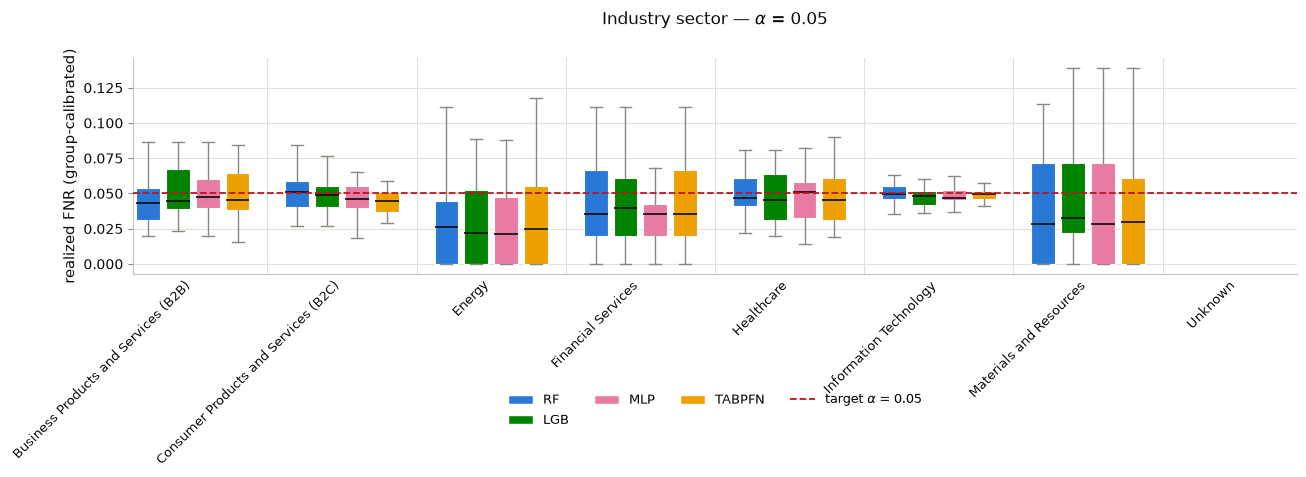

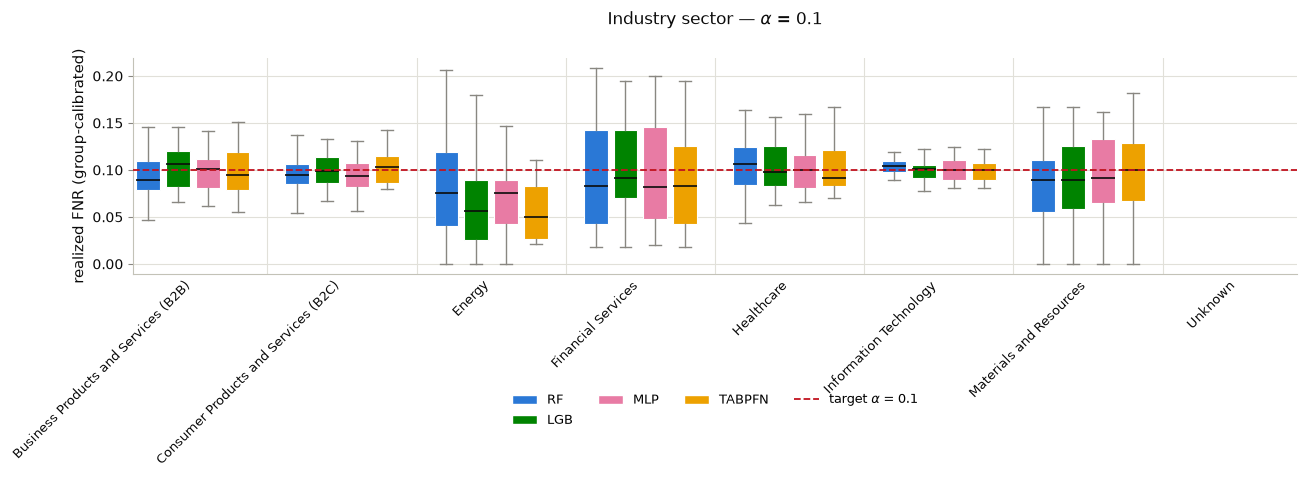

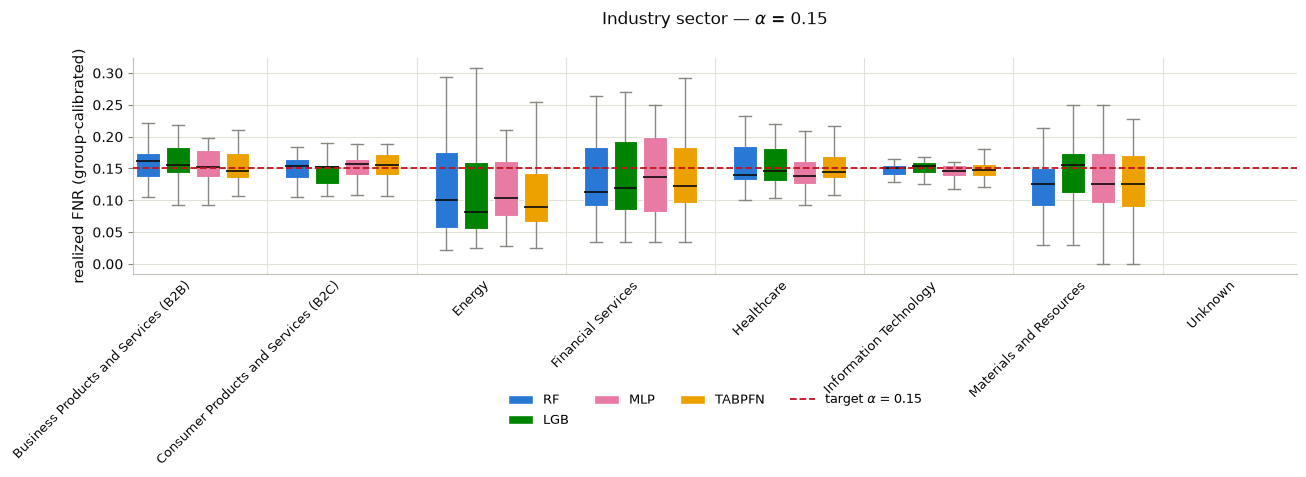

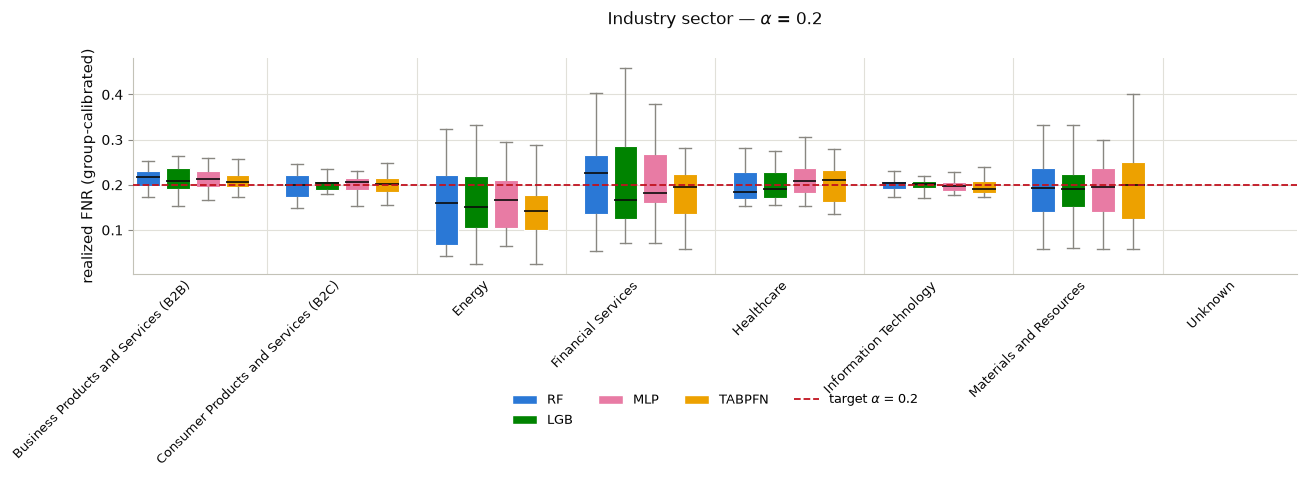

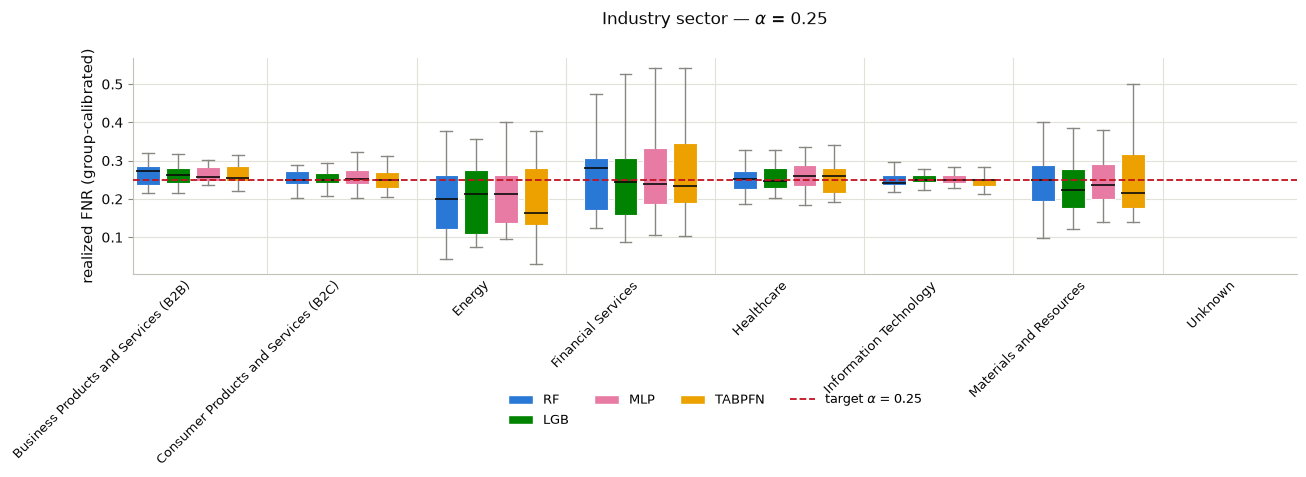

In [14]:
# Industry sector — conditional table then grouped boxplot.
cond_cols = ["group", "alpha", "FNR_marg", "FNR_cond", "FNR_cond - alpha",
             "n_pool", "n_pos_pool", "infeasible"]
dim_name = "Industry sector"
for (model_type, d), tab in subgroup_tables.items():
    if d != dim_name:
        continue
    print(f"=== {model_type.upper()} — {dim_name} (group-calibrated) ===")
    display(tab[cond_cols].rename(columns={"group": dim_name}))

sector_cond = {m: raw for (m, d), raw in subgroup_raw_cond.items() if d == dim_name}
plot_fnr_by_group_boxplots(sector_cond, dim_name, model_color,
                           ylabel="realized FNR (group-calibrated)")

=== RF — YearFounded cohort (group-calibrated) ===


,YearFounded cohort,alpha,FNR_marg,FNR_cond,FNR_cond - alpha,n_pool,n_pos_pool,infeasible
0,2008,0.05,0.028,0.028,NaN,65,29,True
1,2009,0.05,0.019,0.035,NaN,238,99,False
2,2010,0.05,0.016,0.048,NaN,701,253,False
3,2011,0.05,0.056,0.043,NaN,999,308,False
4,2012,0.05,0.037,0.049,NaN,1313,404,False
5,2013,0.05,0.065,0.049,NaN,1657,514,False
6,2014,0.05,0.048,0.049,NaN,1923,663,False
7,2015,0.05,0.058,0.051,0.001,2146,719,False
8,2016,0.05,0.050,0.047,NaN,1794,602,False
9,2017,0.05,0.068,0.051,0.001,1168,338,False


=== LGB — YearFounded cohort (group-calibrated) ===


,YearFounded cohort,alpha,FNR_marg,FNR_cond,FNR_cond - alpha,n_pool,n_pos_pool,infeasible
0,2008,0.05,0.028,0.028,NaN,65,29,True
1,2009,0.05,0.027,0.034,NaN,238,99,False
2,2010,0.05,0.041,0.045,NaN,701,253,False
3,2011,0.05,0.052,0.042,NaN,999,308,False
4,2012,0.05,0.034,0.045,NaN,1313,404,False
5,2013,0.05,0.059,0.050,NaN,1657,514,False
6,2014,0.05,0.043,0.047,NaN,1923,663,False
7,2015,0.05,0.058,0.053,0.003,2146,719,False
8,2016,0.05,0.043,0.049,NaN,1794,602,False
9,2017,0.05,0.085,0.049,NaN,1168,338,False


=== MLP — YearFounded cohort (group-calibrated) ===


,YearFounded cohort,alpha,FNR_marg,FNR_cond,FNR_cond - alpha,n_pool,n_pos_pool,infeasible
0,2008,0.05,0.000,0.000,NaN,65,29,True
1,2009,0.05,0.028,0.034,NaN,238,99,False
2,2010,0.05,0.035,0.049,NaN,701,253,False
3,2011,0.05,0.055,0.043,NaN,999,308,False
4,2012,0.05,0.039,0.052,0.002,1313,404,False
5,2013,0.05,0.060,0.050,NaN,1657,514,False
6,2014,0.05,0.043,0.047,NaN,1923,663,False
7,2015,0.05,0.047,0.049,NaN,2146,719,False
8,2016,0.05,0.057,0.047,NaN,1794,602,False
9,2017,0.05,0.064,0.049,NaN,1168,338,False


=== TABPFN — YearFounded cohort (group-calibrated) ===


,YearFounded cohort,alpha,FNR_marg,FNR_cond,FNR_cond - alpha,n_pool,n_pos_pool,infeasible
0,2008,0.05,0.000,0.000,NaN,65,29,True
1,2009,0.05,0.027,0.037,NaN,238,99,False
2,2010,0.05,0.043,0.050,NaN,701,253,False
3,2011,0.05,0.056,0.045,NaN,999,308,False
4,2012,0.05,0.023,0.046,NaN,1313,404,False
5,2013,0.05,0.057,0.047,NaN,1657,514,False
6,2014,0.05,0.040,0.047,NaN,1923,663,False
7,2015,0.05,0.056,0.051,0.001,2146,719,False
8,2016,0.05,0.057,0.050,NaN,1794,602,False
9,2017,0.05,0.084,0.050,NaN,1168,338,False


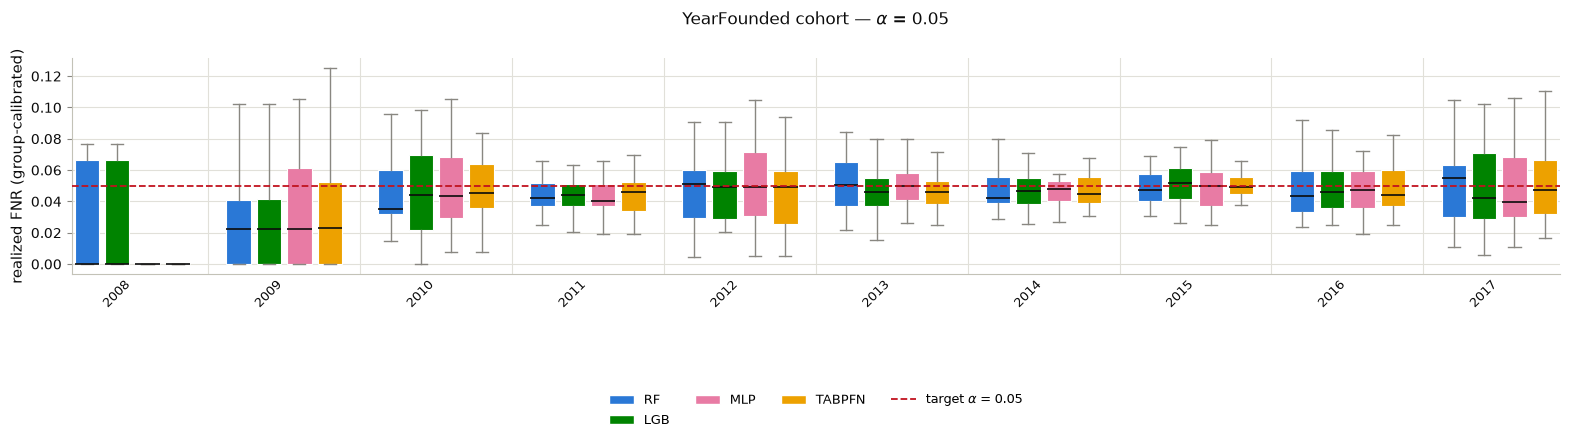

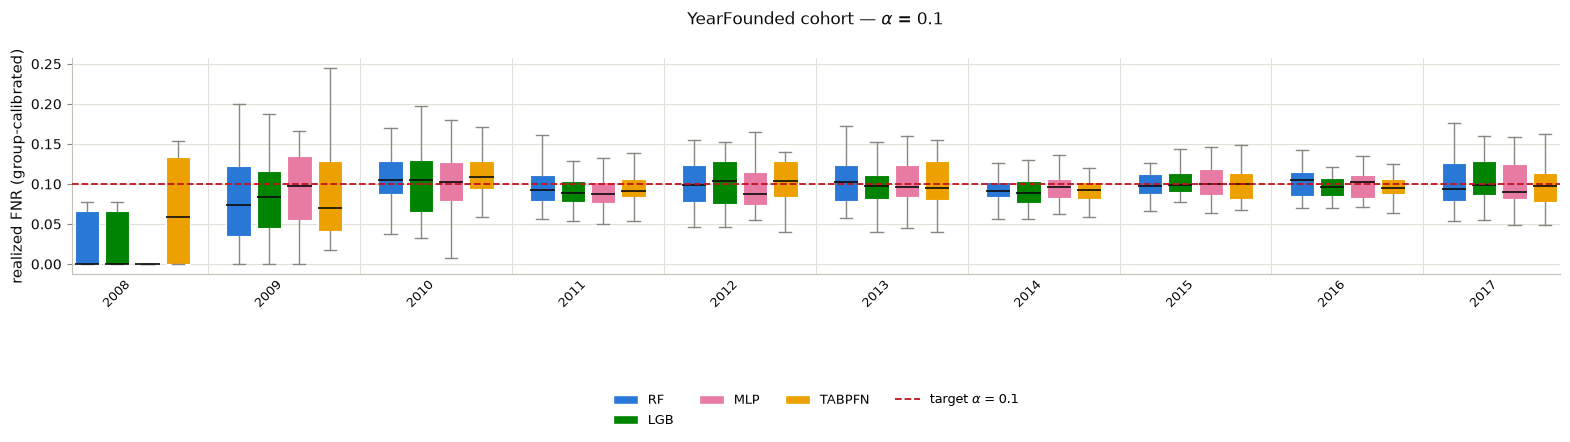

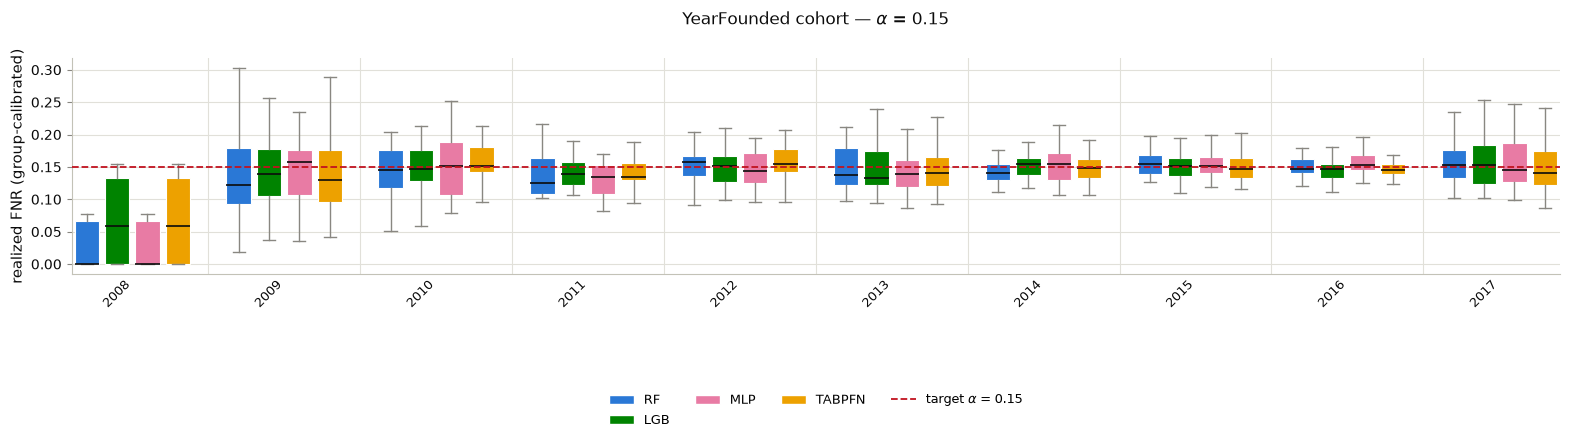

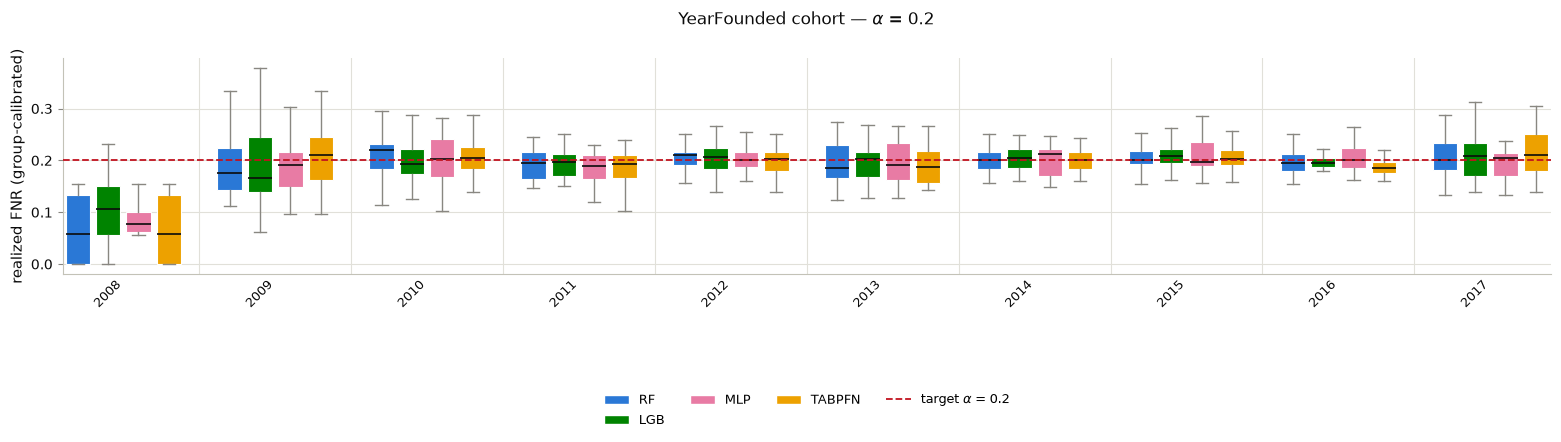

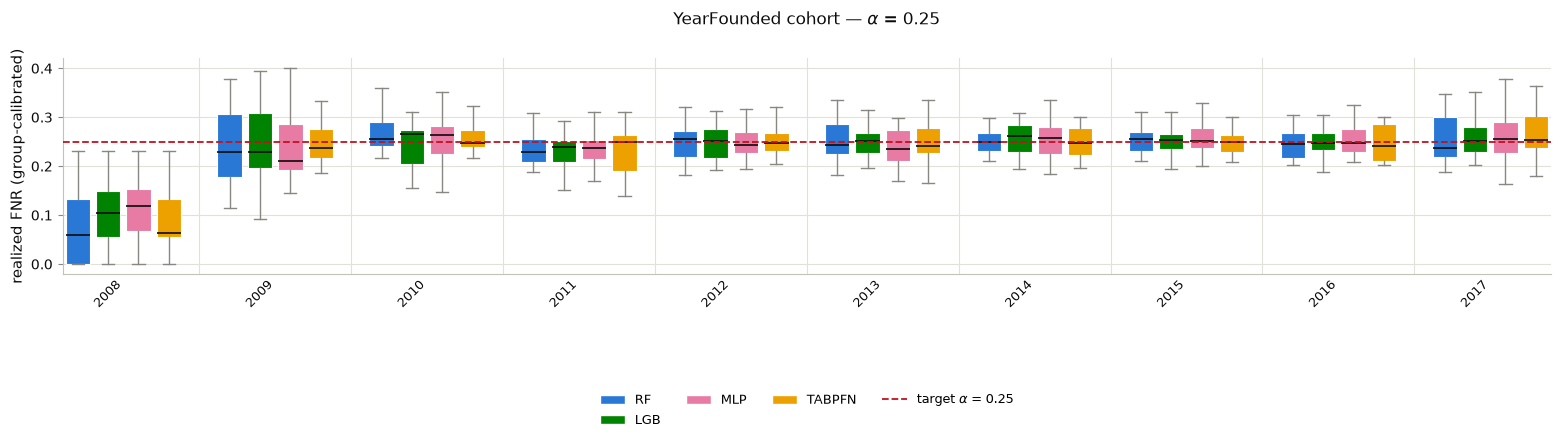

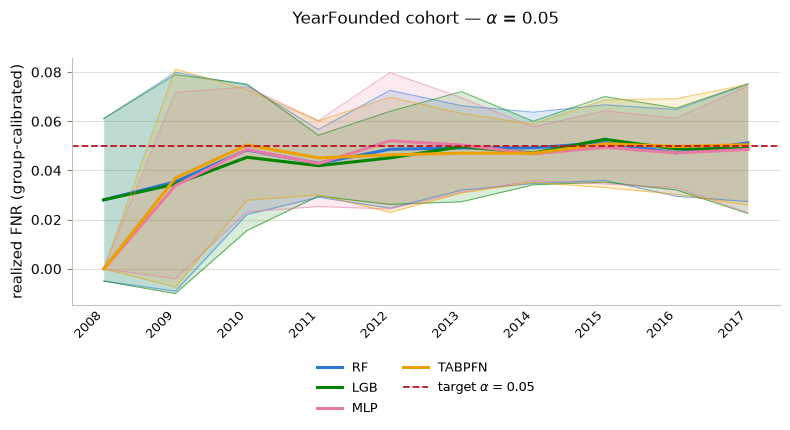

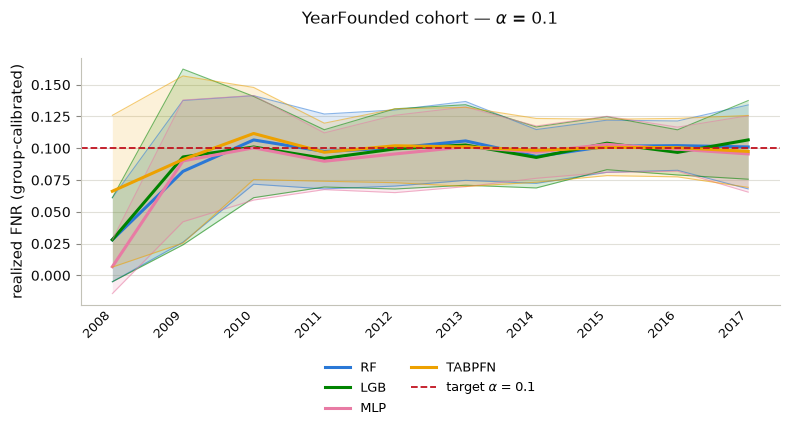

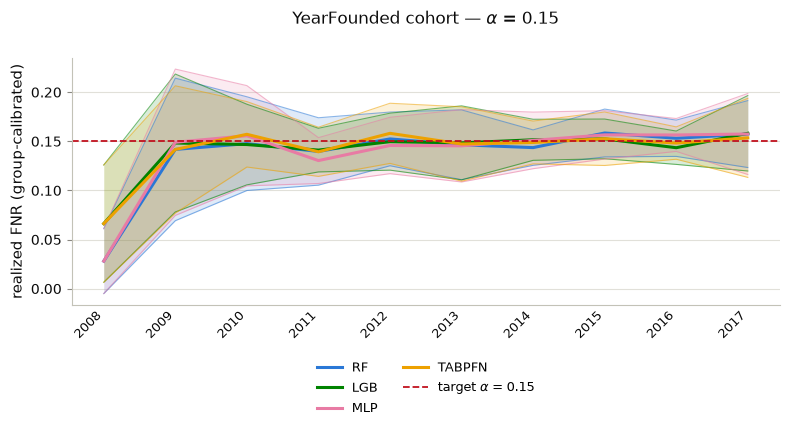

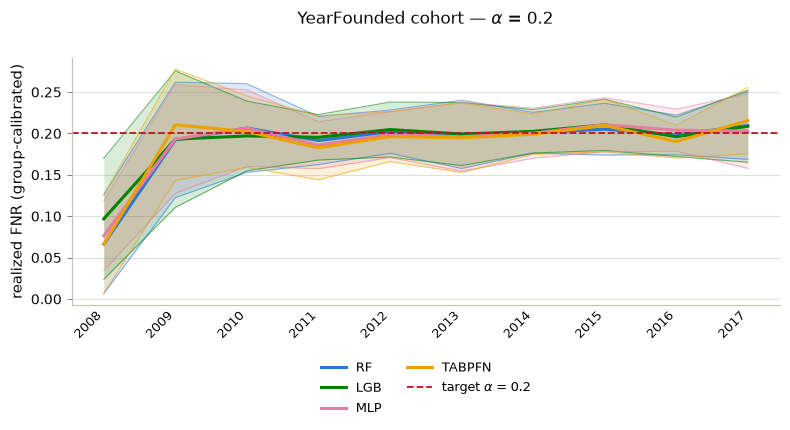

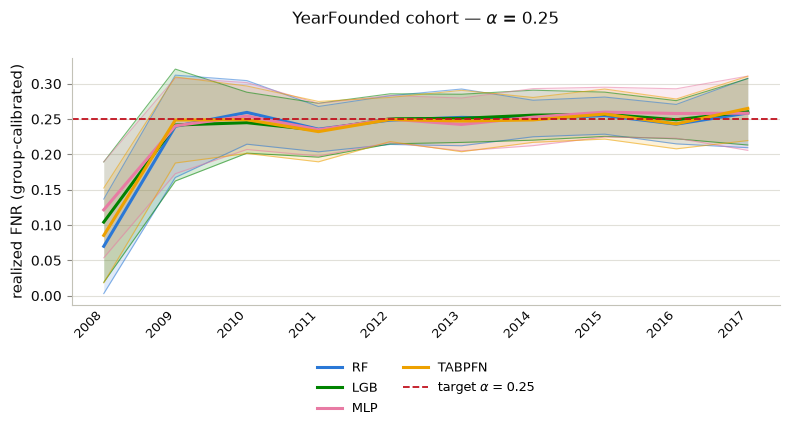

In [15]:
# YearFounded cohort — conditional table, grouped boxplot, per-model line plot.
cond_cols = ["group", "alpha", "FNR_marg", "FNR_cond", "FNR_cond - alpha",
             "n_pool", "n_pos_pool", "infeasible"]
dim_name = "YearFounded cohort"
for (model_type, d), tab in subgroup_tables.items():
    if d != dim_name:
        continue
    print(f"=== {model_type.upper()} — {dim_name} (group-calibrated) ===")
    display(tab[cond_cols].rename(columns={"group": dim_name}))

cohort_cond = {m: raw for (m, d), raw in subgroup_raw_cond.items() if d == dim_name}
plot_fnr_by_group_boxplots(cohort_cond, dim_name, model_color,
                           ylabel="realized FNR (group-calibrated)")
plot_fnr_by_group_lines(cohort_cond, dim_name, model_color,
                        ylabel="realized FNR (group-calibrated)")